# Series de tiempo: pronóstico semanal de WTI y Brent
## Período 2 · Suavizamiento exponencial de Holt con tendencia amortiguada

Se ajusta un modelo independiente para cada crudo usando **solo cotizaciones desde el 01/04/2026**, el período asociado al contexto de guerra en el diseño del TP.

El objetivo es pronosticar los precios diarios en USD por barril de **lunes a viernes de la semana siguiente a la fecha de ejecución en Argentina**. La semana se recalcula al ejecutar todas las celdas. No se programa una ejecución automática.

“Series de tiempo” es una familia de métodos que también incluye ARIMA. Para contar con dos enfoques distintos en el TP, este archivo desarrolla **Holt**; ARIMA se trabajará por separado. Holt estima el nivel y una tendencia que pierde fuerza al extenderse el horizonte. Se compara con mantener el último precio conocido, sin suponer que el método más elaborado necesariamente será mejor.

Las cotizaciones, las predicciones y los errores de validación se presentan por separado: los valores futuros todavía no son observaciones reales.

> **PRUEBA HISTÓRICA SEMANAL · Configuración y resultados**  
> [**IR A LA PRUEBA Y SUS RESULTADOS ↓**](#prueba-historica-semanal) · Sección 10, al final del notebook.  
> Para elegir otra semana, buscar el comentario **CAMBIAR LA SEMANA DE LA PRUEBA** y editar `PRUEBA_LUNES_OBJETIVO`. El corte de entrenamiento y los cinco días a predecir se calculan automáticamente. La sección se puede ejecutar por separado, en orden.

> **NUEVO · PUNTO 11 · PRUEBA ALEATORIA 80 % / 20 %**  
> [**IR AL PUNTO 11 Y SUS RESULTADOS ↓**](#prueba-aleatoria-80-20) · Al final del notebook.  
> Para cambiar el reparto, buscar `# CAMBIAR LOS PORCENTAJES`. Este experimento evalúa precios ocultos dentro de la historia disponible; el pronóstico de una semana futura se evalúa en el punto 10.
> **Incluye parámetros de Holt, tendencia, ADF/KPSS y MAE para ambos métodos.**

In [1]:
from pathlib import Path
import platform

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels
from IPython.display import Markdown, display
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import Holt

plt.style.use("seaborn-v0_8-whitegrid")
COLORES = {"WTI": "#2864A0", "Brent": "#D08023"}

## 1. Configuración de la próxima semana

La opción inicial consulta **EIA** en cada ejecución y aplica los criterios de limpieza del notebook del período 2. Se requiere la clave local ya utilizada en el proyecto. Para trabajar sin conexión se puede cambiar `FUENTE_DATOS` a `"CSV"`; en ese caso se usa la copia de `data/` cuyo nombre tiene el mes más reciente y se informa su fecha de corte.

`FECHA_REFERENCIA = None` utiliza el día actual de Argentina. Para reproducir un corte pasado se puede indicar una fecha como `"2026-10-20"`: se excluyen las cotizaciones posteriores, aunque la fuente consultada hoy puede contener revisiones históricas. El notebook no sobrescribe los CSV.

Los cinco días futuros son una **referencia de lunes a viernes**, no un calendario oficial de publicación de cada crudo. Si una fecha no tiene cotización real, no se debe inventar un precio para evaluarla.

In [2]:
PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

FUENTE_DATOS = "EIA"       # Alternativa sin conexión: "CSV"
FECHA_REFERENCIA = None    # None = hoy en Argentina; o una fecha "AAAA-MM-DD"
ZONA_HORARIA = "America/Argentina/Buenos_Aires"
INICIO_PERIODO_2 = pd.Timestamp("2026-04-01")
N_ORIGENES_VALIDACION = 3
N_SIMULACIONES = 3000
SEMILLA = 42

fecha_referencia = (
    pd.Timestamp.now(tz=ZONA_HORARIA).tz_localize(None).normalize()
    if FECHA_REFERENCIA is None else pd.Timestamp(FECHA_REFERENCIA).normalize()
)
inicio_semana = fecha_referencia + pd.Timedelta(days=7 - fecha_referencia.weekday())
fin_semana = inicio_semana + pd.Timedelta(days=4)
fechas_objetivo = pd.bdate_range(inicio_semana, fin_semana)
if fecha_referencia < INICIO_PERIODO_2:
    raise ValueError("La fecha de referencia debe pertenecer al período 2.")

display(Markdown(
    f"**Fecha de referencia (Argentina):** {fecha_referencia:%d/%m/%Y}.  \n"
    f"**Semana a pronosticar:** {inicio_semana:%d/%m/%Y} a {fin_semana:%d/%m/%Y}.  \n"
    f"**Fuente seleccionada:** {FUENTE_DATOS}."
))

**Fecha de referencia (Argentina):** 20/10/2026.  
**Semana a pronosticar:** 26/10/2026 a 30/10/2026.  
**Fuente seleccionada:** EIA.

## 2. Obtención de los datos

Se consultan los precios spot diarios de EIA para WTI y Brent. La consulta se limita al período 2 y a la fecha de referencia; la fecha de corte real depende de la última publicación recibida. El modelo trabaja con los precios de cada crudo por separado.

In [3]:
if FUENTE_DATOS == "EIA":
    key_path = PROJECT_ROOT / "secret_api_key.txt"
    if not key_path.is_file():
        raise FileNotFoundError(
            "Falta secret_api_key.txt. Configurar la clave de EIA o seleccionar FUENTE_DATOS = 'CSV'."
        )
    api_key = key_path.read_text(encoding="utf-8").strip()
    if not api_key:
        raise ValueError("La clave de EIA está vacía.")
    parametros = {
        "api_key": api_key,
        "frequency": "daily",
        "data[0]": "value",
        "facets[product][]": ["EPCWTI", "EPCBRENT"],
        "start": INICIO_PERIODO_2.strftime("%Y-%m-%d"),
        "end": fecha_referencia.strftime("%Y-%m-%d"),
        "sort[0][column]": "period",
        "sort[0][direction]": "asc",
        "offset": 0,
        "length": 5000,
    }
    try:
        respuesta = requests.get(
            "https://api.eia.gov/v2/petroleum/pri/spt/data/",
            params=parametros,
            timeout=60,
        )
        respuesta.raise_for_status()
    except requests.RequestException as error:
        estado = getattr(error.response, "status_code", "sin respuesta")
        raise RuntimeError(
            f"No se pudo consultar EIA (HTTP: {estado}). "
            "Revisar la conexión o seleccionar FUENTE_DATOS = 'CSV'."
        ) from None
    try:
        contenido = respuesta.json()["response"]
        registros = contenido["data"]
    except (ValueError, KeyError, TypeError):
        raise RuntimeError("EIA no devolvió la estructura de datos esperada.") from None
    if int(contenido.get("total", len(registros))) > len(registros):
        raise ValueError("La respuesta de EIA está incompleta; se necesita paginación.")
    datos_originales = pd.DataFrame(registros)
    origen = "API EIA · precios spot diarios"
    del api_key, parametros, respuesta
elif FUENTE_DATOS == "CSV":
    archivos = sorted((PROJECT_ROOT / "data").glob("eia_precios_crudo_diarios_*.csv"))
    if not archivos:
        raise FileNotFoundError("No se encontró un CSV local de precios diarios.")
    csv_path = archivos[-1]
    # El texto literal 'NA' de area_name no se interpreta como un dato faltante.
    datos_originales = pd.read_csv(csv_path, keep_default_na=False)
    origen = f"CSV local · {csv_path.name}"
else:
    raise ValueError("FUENTE_DATOS debe ser 'EIA' o 'CSV'.")

print(f"Origen: {origen}")
print(f"Filas recibidas: {len(datos_originales):,}")

Origen: API EIA · precios spot diarios
Filas recibidas: 274


## 3. Limpieza y validación

Se mantiene la lógica ya utilizada en `periodo_2_wti_brent.ipynb`: se conserva la tabla original, se normalizan los textos, se convierten fechas y precios, y se eliminan duplicados completos. Los duplicados por fecha y crudo, los nulos y los precios no finitos detienen el ajuste.

Para la fuente CSV, primero se selecciona el período 2 hasta el corte indicado. **Ningún precio de otro período entra en el ajuste, las ventanas móviles o la validación.** No se rellenan fines de semana, feriados ni cotizaciones ausentes.

In [4]:
df_periodo_2_limpio = datos_originales.copy()
df_periodo_2_limpio.columns = df_periodo_2_limpio.columns.str.replace("_", "-", regex=False)
requeridas = {"period", "series", "value"}
if not requeridas.issubset(df_periodo_2_limpio.columns):
    raise ValueError("Faltan columnas de fecha, serie o precio.")

for columna in df_periodo_2_limpio.columns.difference(["period", "value"]):
    df_periodo_2_limpio[columna] = (
        df_periodo_2_limpio[columna].astype("string").str.strip().replace("", pd.NA)
    )
df_periodo_2_limpio["period"] = pd.to_datetime(
    df_periodo_2_limpio["period"], errors="coerce"
)
df_periodo_2_limpio["value"] = pd.to_numeric(
    df_periodo_2_limpio["value"], errors="coerce"
)
if df_periodo_2_limpio["period"].isna().any():
    raise ValueError("Hay fechas inválidas en la fuente.")

en_periodo = df_periodo_2_limpio["period"].between(INICIO_PERIODO_2, fecha_referencia)
filas_excluidas = int((~en_periodo).sum())
df_periodo_2_limpio = df_periodo_2_limpio.loc[en_periodo].copy()
duplicados_eliminados = int(df_periodo_2_limpio.duplicated().sum())
df_periodo_2_limpio = df_periodo_2_limpio.drop_duplicates().reset_index(drop=True)
if df_periodo_2_limpio.empty:
    raise ValueError("No hay datos para el período 2 hasta la fecha de referencia.")
if not df_periodo_2_limpio["series"].isin(["RWTC", "RBRTE"]).all():
    raise ValueError("La fuente contiene una serie distinta de WTI o Brent.")

textos = df_periodo_2_limpio.select_dtypes(include=["object", "string"])
validacion_limpieza = pd.DataFrame({
    "Control": [
        "Nulos", "Cadenas vacías", "Valores con solo espacios",
        "Duplicados completos", "Duplicados por fecha y serie",
    ],
    "Cantidad": [
        int(df_periodo_2_limpio.isna().sum().sum()),
        int(textos.eq("").sum().sum()),
        sum(int(textos[c].str.fullmatch(r"\s+", na=False).sum()) for c in textos),
        int(df_periodo_2_limpio.duplicated().sum()),
        int(df_periodo_2_limpio.duplicated(["period", "series"]).sum()),
    ],
})
validacion_limpieza["Estado"] = np.where(validacion_limpieza["Cantidad"].eq(0), "OK", "REVISAR")
display(validacion_limpieza)
print(f"Filas excluidas por estar fuera del período/corte: {filas_excluidas}")
print(f"Duplicados completos eliminados: {duplicados_eliminados}")
if not validacion_limpieza["Cantidad"].eq(0).all():
    raise ValueError("Resolver los problemas de limpieza antes de ajustar.")
if not np.isfinite(df_periodo_2_limpio["value"]).all():
    raise ValueError("Hay precios no finitos.")

,Control,Cantidad,Estado
0,Nulos,0,OK
1,Cadenas vacías,0,OK
2,Valores con solo espacios,0,OK
3,Duplicados completos,0,OK
4,Duplicados por fecha y serie,0,OK


Filas excluidas por estar fuera del período/corte: 0
Duplicados completos eliminados: 0


## 4. Series y horizonte real del pronóstico

Cada serie conserva sus propias fechas y cotizaciones válidas. Para ajustar Holt se utilizan observaciones consecutivas: un paso equivale a la siguiente cotización disponible, aunque entre dos precios puedan transcurrir varios días calendario.

Para colocar los pronósticos futuros se supone una cotización por día de lunes a viernes. Se informa todo el recorrido desde el último precio hasta el viernes objetivo. **Pronosticar una semana concreta puede requerir más de cinco pasos** si faltan publicaciones recientes. Esta aproximación de calendario se debe revisar al comparar luego con precios reales.

,Crudo,Primera cotización,Última cotización,Cotizaciones,Demora al corte (días calendario),Pasos totales,Pasos de la semana objetivo
0,WTI,2026-04-01,2026-10-14,138,6,12,8 a 12
1,Brent,2026-04-01,2026-10-14,136,6,12,8 a 12


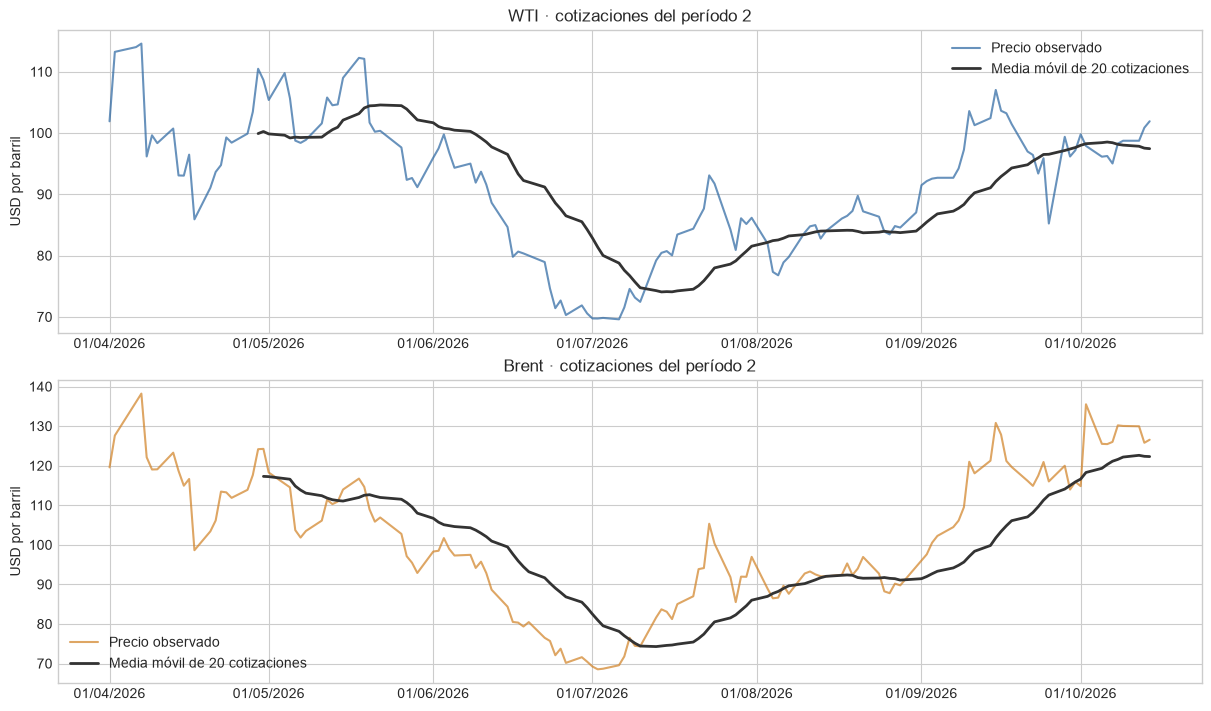

La media móvil ayuda a leer la evolución histórica; el pronóstico se obtiene con Holt. Las 20 observaciones de la ventana no equivalen a 20 días calendario.

In [5]:
series_periodo_2 = {}
fechas_futuras = {}
horizontes = {}
filas_cobertura = []
for crudo, codigo in {"WTI": "RWTC", "Brent": "RBRTE"}.items():
    muestra = df_periodo_2_limpio.loc[
        df_periodo_2_limpio["series"].eq(codigo), ["period", "value"]
    ].sort_values("period")
    serie = muestra.set_index("period")["value"].astype(float).rename(crudo)
    if len(serie) < 40:
        raise ValueError(f"{crudo}: se requieren al menos 40 cotizaciones.")
    if serie.index.max() >= inicio_semana:
        raise ValueError("Hay datos de la semana objetivo dentro del entrenamiento.")
    futuro = pd.bdate_range(serie.index.max() + pd.Timedelta(days=1), fin_semana)
    if not fechas_objetivo.isin(futuro).all():
        raise ValueError("El calendario futuro no incluye toda la semana objetivo.")
    series_periodo_2[crudo] = serie
    fechas_futuras[crudo] = futuro
    horizontes[crudo] = len(futuro)
    posiciones_objetivo = np.flatnonzero(futuro.isin(fechas_objetivo)) + 1
    filas_cobertura.append({
        "Crudo": crudo,
        "Primera cotización": serie.index.min().date(),
        "Última cotización": serie.index.max().date(),
        "Cotizaciones": len(serie),
        "Demora al corte (días calendario)": (fecha_referencia - serie.index.max()).days,
        "Pasos totales": len(futuro),
        "Pasos de la semana objetivo": f"{posiciones_objetivo[0]} a {posiciones_objetivo[-1]}",
    })
cobertura = pd.DataFrame(filas_cobertura)
display(cobertura)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
for ax, (crudo, serie) in zip(axes, series_periodo_2.items()):
    ax.plot(serie.index, serie, color=COLORES[crudo], alpha=0.7, label="Precio observado")
    ax.plot(serie.index, serie.rolling(20, min_periods=20).mean(),
            color="#333333", linewidth=2, label="Media móvil de 20 cotizaciones")
    ax.set(title=f"{crudo} · cotizaciones del período 2", ylabel="USD por barril")
    ax.legend(loc="best")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
plt.show()
display(Markdown(
    "La media móvil ayuda a leer la evolución histórica; el pronóstico se obtiene con Holt. "
    "Las 20 observaciones de la ventana no equivalen a 20 días calendario."
))

## 5. Modelo clásico: Holt con tendencia amortiguada

El método actualiza dos componentes: el **nivel** (precio suavizado) y la **tendencia** (cambio estimado por cotización). Los parámetros se estiman con los datos disponibles en cada entrenamiento.

\[
\ell_t=\alpha y_t+(1-\alpha)(\ell_{t-1}+\phi b_{t-1})
\]
\[
b_t=\beta(\ell_t-\ell_{t-1})+(1-\beta)\phi b_{t-1}
\]
\[
\hat y_{T+h\mid T}=\ell_T+(\phi+\phi^2+\cdots+\phi^h)b_T
\]

Aquí \(\alpha\) y \(\beta\) controlan las actualizaciones, y \(\phi\) amortigua la tendencia. Se usa una forma aditiva sobre los precios, sin componente estacional. No requiere diferenciar previamente la serie. La elección es un punto de comparación académico; su precisión se evalúa con datos posteriores al entrenamiento.

Referencia del método: [Hyndman y Athanasopoulos, métodos con tendencia](https://otexts.com/fpp3/holt.html). Implementación: [statsmodels, suavizamiento exponencial](https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html).

In [6]:
def ajustar_holt(serie):
    """Ajuste separado, con valores ordenados y sin usar fechas futuras."""
    valores = np.asarray(serie, dtype=float)
    if len(valores) < 40 or not np.isfinite(valores).all():
        raise ValueError("El entrenamiento necesita 40 precios válidos como mínimo.")
    ajuste = Holt(
        valores,
        exponential=False,
        damped_trend=True,
        initialization_method="estimated",
    ).fit(optimized=True)
    if not ajuste.mle_retvals.get("success", True):
        raise RuntimeError("El ajuste de Holt no convergió.")
    return ajuste


def calcular_metricas(real, predicho):
    error = np.asarray(real, dtype=float) - np.asarray(predicho, dtype=float)
    return {
        "MAE (USD/barril)": float(np.mean(np.abs(error))),
        "RMSE (USD/barril)": float(np.sqrt(np.mean(error ** 2))),
    }

## 6. Validación temporal frente al último precio

Se utilizan **tres cortes históricos** que avanzan de a cinco cotizaciones, todos dentro del período 2. En cada corte:

1. Se ajusta Holt únicamente con el pasado.
2. Se pronostica el mismo número de pasos que exige hoy llegar al viernes objetivo.
3. Se evalúan los últimos cinco pasos de ese recorrido. Las tres ventanas evaluadas no se superponen.
4. Se compara con el método ingenuo: repetir el último precio del entrenamiento.

Así se respeta el intervalo previo a la semana objetivo, en lugar de evaluar solo cinco pasos cuando el pronóstico real exige más. Los pasos históricos cuentan cotizaciones, por lo que su duración calendario puede variar. **MAE** mide el error absoluto promedio y **RMSE** da mayor peso a errores grandes; cuanto menores, mejor. Se mantienen fijos el tipo de modelo y este diseño: la validación no se utiliza para elegir parámetros manualmente.

Referencia: [evaluación temporal de pronósticos](https://otexts.com/fpp3/tscv.html).

In [7]:
filas_errores = []
filas_ventanas = []
ultimas_validaciones = {}
for crudo, serie in series_periodo_2.items():
    h = horizontes[crudo]
    primer_origen = len(serie) - h - (N_ORIGENES_VALIDACION - 1) * 5
    if primer_origen < 40:
        raise ValueError(
            f"{crudo}: faltan datos para validar un horizonte de {h} pasos. "
            "Actualizar la fuente o revisar la fecha de referencia."
        )
    for numero in range(N_ORIGENES_VALIDACION):
        origen_idx = primer_origen + numero * 5
        entrenamiento = serie.iloc[:origen_idx]
        observado = serie.iloc[origen_idx:origen_idx + h]
        ajuste = ajustar_holt(entrenamiento)
        pred_holt = np.asarray(ajuste.forecast(h), dtype=float)
        pred_ingenuo = np.repeat(entrenamiento.iloc[-1], h)
        evaluado = observado.iloc[-5:]
        filas_ventanas.append({
            "Crudo": crudo, "Corte": numero + 1, "n entrenamiento": len(entrenamiento),
            "Último dato entrenado": entrenamiento.index[-1].date(),
            "Evaluación desde": evaluado.index[0].date(),
            "Evaluación hasta": evaluado.index[-1].date(),
            "Pasos totales": h, "Pasos evaluados": 5,
        })
        for modelo, predicciones in [("Holt amortiguado", pred_holt), ("Último precio", pred_ingenuo)]:
            for fecha, real, predicho in zip(evaluado.index, evaluado, predicciones[-5:]):
                filas_errores.append({
                    "Crudo": crudo, "Corte": numero + 1, "Modelo": modelo,
                    "Fecha": fecha, "Real": real, "Predicho": predicho,
                })
        ultimas_validaciones[crudo] = {
            "entrenamiento": entrenamiento, "observado": observado,
            "Holt": pred_holt, "Ingenuo": pred_ingenuo,
        }

ventanas_validacion = pd.DataFrame(filas_ventanas)
predicciones_validacion = pd.DataFrame(filas_errores)
filas_metricas = []
for (crudo, modelo), grupo in predicciones_validacion.groupby(["Crudo", "Modelo"], sort=False):
    if grupo["Fecha"].duplicated().any():
        raise AssertionError("Las ventanas de evaluación se superponen.")
    filas_metricas.append({
        "Crudo": crudo, "Modelo": modelo, "Predicciones evaluadas": len(grupo),
        **calcular_metricas(grupo["Real"], grupo["Predicho"]),
    })
metricas_validacion = pd.DataFrame(filas_metricas)
display(ventanas_validacion)
display(metricas_validacion.style.format({
    "MAE (USD/barril)": "{:.2f}", "RMSE (USD/barril)": "{:.2f}",
}))

,Crudo,Corte,n entrenamiento,Último dato entrenado,Evaluación desde,Evaluación hasta,Pasos totales,Pasos evaluados
0,WTI,1,116,2026-09-14,2026-09-24,2026-09-30,12,5
1,WTI,2,121,2026-09-21,2026-10-01,2026-10-07,12,5
2,WTI,3,126,2026-09-28,2026-10-08,2026-10-14,12,5
3,Brent,1,114,2026-09-14,2026-09-24,2026-09-30,12,5
4,Brent,2,119,2026-09-21,2026-10-01,2026-10-07,12,5
5,Brent,3,124,2026-09-28,2026-10-08,2026-10-14,12,5


,Crudo,Modelo,Predicciones evaluadas,MAE (USD/barril),RMSE (USD/barril)
0,WTI,Holt amortiguado,15,3.48,5.40
1,WTI,Último precio,15,3.46,5.41
2,Brent,Holt amortiguado,15,7.55,8.88
3,Brent,Último precio,15,7.42,8.72


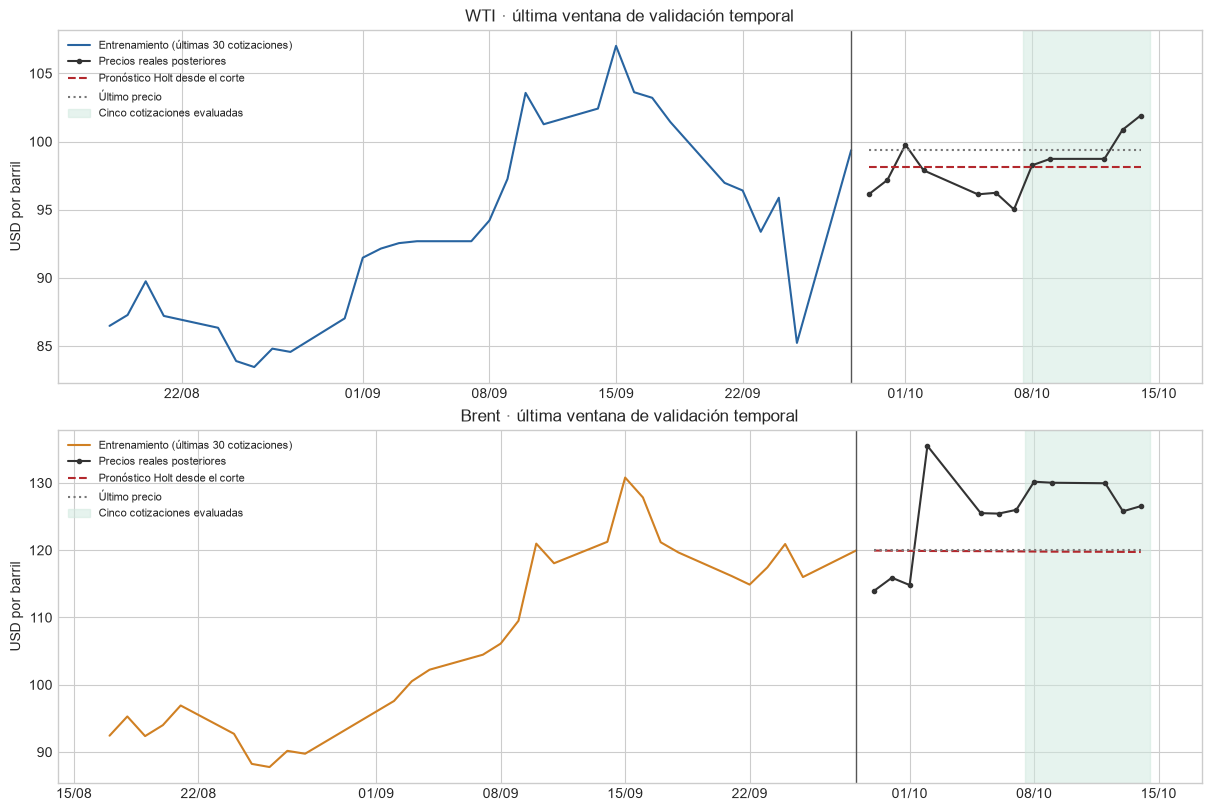

**WTI:** MAE de Holt = **3.48 USD/barril**; MAE del último precio = **3.46 USD/barril**. En estas ventanas, mantener el último precio presenta menor MAE que Holt. Son 15 cotizaciones evaluadas por método: el resultado es una evidencia acotada y no demuestra que un método será superior en todas las semanas.

**Brent:** MAE de Holt = **7.55 USD/barril**; MAE del último precio = **7.42 USD/barril**. En estas ventanas, mantener el último precio presenta menor MAE que Holt. Son 15 cotizaciones evaluadas por método: el resultado es una evidencia acotada y no demuestra que un método será superior en todas las semanas.

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, (crudo, caso) in zip(axes, ultimas_validaciones.items()):
    entrenamiento, observado = caso["entrenamiento"], caso["observado"]
    ax.plot(entrenamiento.tail(30).index, entrenamiento.tail(30),
            color=COLORES[crudo], label="Entrenamiento (últimas 30 cotizaciones)")
    ax.plot(observado.index, observado, color="#333333", marker="o", markersize=3,
            label="Precios reales posteriores")
    ax.plot(observado.index, caso["Holt"], color="#B3282D", linestyle="--",
            label="Pronóstico Holt desde el corte")
    ax.plot(observado.index, caso["Ingenuo"], color="#777777", linestyle=":",
            label="Último precio")
    ax.axvline(entrenamiento.index[-1], color="#555555", linewidth=1)
    ax.axvspan(observado.index[-5] - pd.Timedelta(hours=12),
               observado.index[-1] + pd.Timedelta(hours=12), color="#CFE8DE", alpha=0.5,
               label="Cinco cotizaciones evaluadas")
    ax.set(title=f"{crudo} · última ventana de validación temporal", ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(loc="best", fontsize=8)
plt.show()

for crudo in series_periodo_2:
    tabla = metricas_validacion.loc[metricas_validacion["Crudo"].eq(crudo)].set_index("Modelo")
    mae_holt = tabla.loc["Holt amortiguado", "MAE (USD/barril)"]
    mae_ingenuo = tabla.loc["Último precio", "MAE (USD/barril)"]
    if np.isclose(mae_holt, mae_ingenuo):
        lectura = "ambos métodos presentan un MAE prácticamente igual"
    elif mae_holt < mae_ingenuo:
        lectura = "Holt presenta menor MAE que mantener el último precio"
    else:
        lectura = "mantener el último precio presenta menor MAE que Holt"
    display(Markdown(
        f"**{crudo}:** MAE de Holt = **{mae_holt:.2f} USD/barril**; "
        f"MAE del último precio = **{mae_ingenuo:.2f} USD/barril**. En estas ventanas, {lectura}. "
        "Son 15 cotizaciones evaluadas por método: el resultado es una evidencia acotada "
        "y no demuestra que un método será superior en todas las semanas."
    ))

## 7. Ajuste final y pronóstico de la próxima semana

Después de medir los errores históricos se vuelve a ajustar Holt con **todo el período 2 disponible hasta el corte**. Los precios usados antes para validar ahora pertenecen al pasado conocido y pueden utilizarse en este ajuste final.

Se generan 3.000 trayectorias con errores remuestreados de los residuos centrados del ajuste. Los percentiles 2,5 y 97,5 forman una **banda de predicción aproximada del 95%**, condicionada al modelo y a los parámetros estimados. El remuestreo supone errores independientes y una variabilidad semejante a la observada; no incorpora toda la incertidumbre de parámetros ni acontecimientos nuevos. La banda no tiene una cobertura del 95% comprobada en este TP.

Documentación: [simulación de trayectorias de Holt en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.HoltWintersResults.simulate.html).

In [9]:
ajustes_finales = {}
trayectorias_pronostico = {}
filas_parametros = []
for i, (crudo, serie) in enumerate(series_periodo_2.items()):
    ajuste = ajustar_holt(serie)
    ajustes_finales[crudo] = ajuste
    futuro = fechas_futuras[crudo]
    h = len(futuro)
    puntual = np.asarray(ajuste.forecast(h), dtype=float)
    residuos = np.asarray(ajuste.resid, dtype=float)
    residuos_centrados = residuos - residuos.mean()
    rng = np.random.default_rng(SEMILLA + i)
    errores = rng.choice(residuos_centrados, size=(h, N_SIMULACIONES), replace=True)
    simulaciones = np.asarray(ajuste.simulate(
        nsimulations=h, anchor="end", repetitions=N_SIMULACIONES,
        error="add", random_errors=errores,
    ))
    inferior, superior = np.quantile(simulaciones, [0.025, 0.975], axis=1)
    if not np.isfinite(puntual).all() or not np.isfinite(simulaciones).all():
        raise RuntimeError(f"{crudo}: se obtuvieron pronósticos no finitos.")
    trayectorias_pronostico[crudo] = pd.DataFrame({
        "Crudo": crudo, "Fecha": futuro, "Paso desde último dato": np.arange(1, h + 1),
        "Holt (USD/barril)": puntual, "Inferior 95% aprox.": inferior,
        "Superior 95% aprox.": superior, "Último precio (referencia)": serie.iloc[-1],
    })
    filas_parametros.append({
        "Crudo": crudo, "n": len(serie), "Alfa (nivel)": ajuste.params["smoothing_level"],
        "Beta (tendencia)": ajuste.params["smoothing_trend"],
        "Phi (amortiguación)": ajuste.params["damping_trend"],
        "Nivel final": ajuste.level[-1], "Tendencia final por cotización": ajuste.trend[-1],
    })

parametros_finales = pd.DataFrame(filas_parametros)
pronostico_completo = pd.concat(trayectorias_pronostico.values(), ignore_index=True)
pronostico_semana = pronostico_completo.loc[
    pronostico_completo["Fecha"].isin(fechas_objetivo)
].reset_index(drop=True)
if not pronostico_semana.groupby("Crudo").size().eq(5).all():
    raise AssertionError("Se esperaban cinco fechas objetivo por crudo.")
display(parametros_finales.style.format(precision=4))
display(Markdown(
    f"### Semana del {inicio_semana:%d/%m/%Y} al {fin_semana:%d/%m/%Y}\n"
    "Todos los precios y límites de la tabla se expresan en USD por barril."
))
display(pronostico_semana.style.format({
    "Fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
    "Holt (USD/barril)": "{:.2f}", "Inferior 95% aprox.": "{:.2f}",
    "Superior 95% aprox.": "{:.2f}", "Último precio (referencia)": "{:.2f}",
}))

,Crudo,n,Alfa (nivel),Beta (tendencia),Phi (amortiguación),Nivel final,Tendencia final por cotización
0,WTI,138,0.8824,0.0000,0.9758,101.7552,-0.0129
1,Brent,136,0.9365,0.0000,0.9707,126.5170,-0.0145


### Semana del 26/10/2026 al 30/10/2026
Todos los precios y límites de la tabla se expresan en USD por barril.

,Crudo,Fecha,Paso desde último dato,Holt (USD/barril),Inferior 95% aprox.,Superior 95% aprox.,Último precio (referencia)
0,WTI,26/10/2026,8,101.66,79.98,120.94,101.91
1,WTI,27/10/2026,9,101.65,79.76,121.46,101.91
2,WTI,28/10/2026,10,101.64,78.58,122.02,101.91
3,WTI,29/10/2026,11,101.63,77.97,122.95,101.91
4,WTI,30/10/2026,12,101.62,76.86,124.27,101.91
5,Brent,26/10/2026,8,126.42,101.65,152.01,126.55
6,Brent,27/10/2026,9,126.40,99.92,153.38,126.55
7,Brent,28/10/2026,10,126.39,98.67,154.62,126.55
8,Brent,29/10/2026,11,126.38,97.65,154.96,126.55
9,Brent,30/10/2026,12,126.37,95.46,157.04,126.55


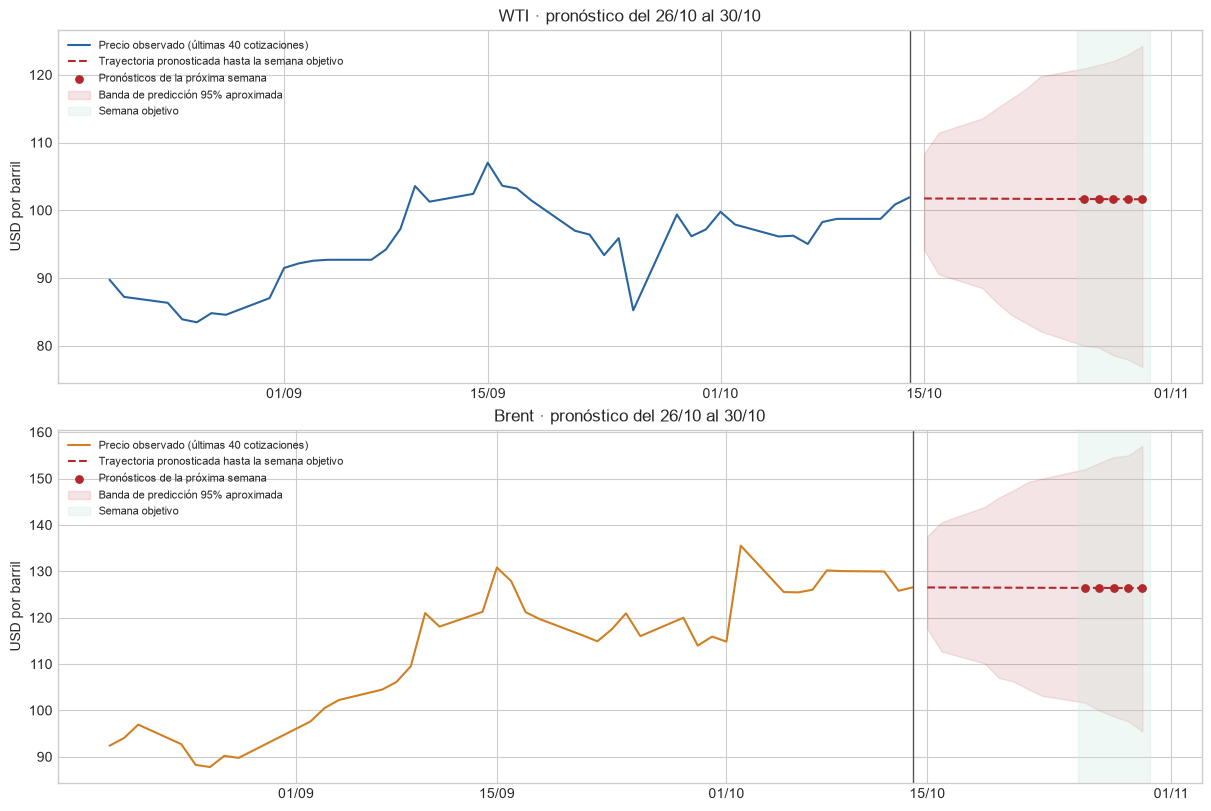

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, (crudo, serie) in zip(axes, series_periodo_2.items()):
    futuro = trayectorias_pronostico[crudo]
    objetivo = futuro.loc[futuro["Fecha"].isin(fechas_objetivo)]
    ax.plot(serie.tail(40).index, serie.tail(40), color=COLORES[crudo],
            label="Precio observado (últimas 40 cotizaciones)")
    ax.plot(futuro["Fecha"], futuro["Holt (USD/barril)"], color="#B3282D",
            linestyle="--", label="Trayectoria pronosticada hasta la semana objetivo")
    ax.scatter(objetivo["Fecha"], objetivo["Holt (USD/barril)"], color="#B3282D", s=28,
               zorder=4, label="Pronósticos de la próxima semana")
    ax.fill_between(
        futuro["Fecha"], futuro["Inferior 95% aprox."], futuro["Superior 95% aprox."],
        color="#B3282D", alpha=0.12, label="Banda de predicción 95% aproximada",
    )
    ax.axvline(serie.index[-1], color="#555555", linewidth=1)
    ax.axvspan(inicio_semana - pd.Timedelta(hours=12), fin_semana + pd.Timedelta(hours=12),
               color="#CFE8DE", alpha=0.3, label="Semana objetivo")
    ax.set(title=f"{crudo} · pronóstico del {inicio_semana:%d/%m} al {fin_semana:%d/%m}",
           ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(loc="best", fontsize=8)
plt.show()

## 8. Residuos y límites de la interpretación

Los residuos son diferencias entre precios observados y ajustes de un paso dentro del entrenamiento. Sirven para explorar lo que el modelo no explica; **no reemplazan los errores de la validación temporal**.

La autocorrelación de los residuos puede mostrar dependencia pendiente de modelar. Las bandas del gráfico son referencias puntuales aproximadas; no certifican que los errores sean independientes ni que los intervalos futuros estén calibrados.

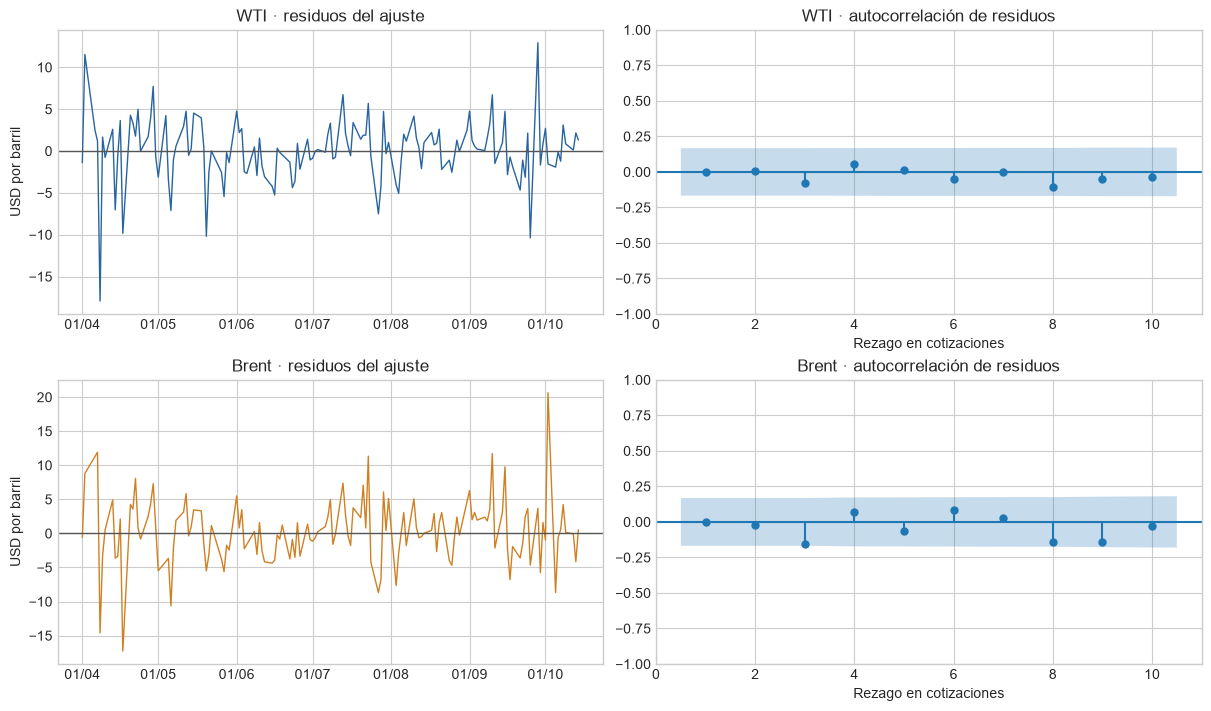

,Crudo,Media residual,Desvío residual,Autocorrelación de rezago 1
0,WTI,0.106,3.850,-0.000
1,Brent,0.255,4.843,-0.001


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
filas_residuos = []
for fila, (crudo, serie) in enumerate(series_periodo_2.items()):
    resid = pd.Series(ajustes_finales[crudo].resid, index=serie.index)
    axes[fila, 0].plot(resid.index, resid, color=COLORES[crudo], linewidth=1)
    axes[fila, 0].axhline(0, color="#555555", linewidth=1)
    axes[fila, 0].set(title=f"{crudo} · residuos del ajuste", ylabel="USD por barril")
    axes[fila, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    plot_acf(resid.to_numpy(), lags=10, zero=False, ax=axes[fila, 1],
             title=f"{crudo} · autocorrelación de residuos")
    axes[fila, 1].set_xlabel("Rezago en cotizaciones")
    filas_residuos.append({
        "Crudo": crudo, "Media residual": resid.mean(),
        "Desvío residual": resid.std(ddof=1), "Autocorrelación de rezago 1": resid.autocorr(1),
    })
plt.show()
display(pd.DataFrame(filas_residuos).style.format(precision=3))

## 9. Lectura para el TP

El método usa precios observados durante el período de guerra definido por el grupo, pero no contiene variables que describan decisiones políticas o eventos bélicos. Su resultado depende de que la dinámica reciente conserve cierta continuidad.

Al volver a ejecutar todas las celdas, se recalculan la próxima semana, los datos disponibles, la validación y los pronósticos. Si se utiliza CSV, es necesario actualizar esa copia para incorporar nuevas publicaciones. La fecha impresa en las salidas permite saber a qué ejecución corresponde cada resultado.

No se declara a Holt superior a ARIMA: todavía falta implementar y evaluar ese segundo modelo bajo **los mismos cortes, horizontes y métricas**.

In [12]:
for crudo, serie in series_periodo_2.items():
    semana = pronostico_semana.loc[pronostico_semana["Crudo"].eq(crudo)]
    promedio = semana["Holt (USD/barril)"].mean()
    display(Markdown(
        f"**{crudo}.** Con {len(serie)} cotizaciones desde {serie.index.min():%d/%m/%Y} "
        f"hasta {serie.index.max():%d/%m/%Y}, Holt estima un promedio de los cinco "
        f"pronósticos de **{promedio:.2f} USD/barril** para la semana objetivo. "
        f"El último precio observado fue **{serie.iloc[-1]:.2f} USD/barril**. "
        "El promedio resume las predicciones diarias; no es un precio semanal ya observado."
    ))

display(pd.DataFrame({
    "Componente": ["Python", "pandas", "NumPy", "statsmodels", "Fuente", "Referencia Argentina"],
    "Valor": [platform.python_version(), pd.__version__, np.__version__,
              statsmodels.__version__, origen, fecha_referencia.strftime("%Y-%m-%d")],
}))

**WTI.** Con 138 cotizaciones desde 01/04/2026 hasta 14/10/2026, Holt estima un promedio de los cinco pronósticos de **101.64 USD/barril** para la semana objetivo. El último precio observado fue **101.91 USD/barril**. El promedio resume las predicciones diarias; no es un precio semanal ya observado.

**Brent.** Con 136 cotizaciones desde 01/04/2026 hasta 14/10/2026, Holt estima un promedio de los cinco pronósticos de **126.39 USD/barril** para la semana objetivo. El último precio observado fue **126.55 USD/barril**. El promedio resume las predicciones diarias; no es un precio semanal ya observado.

,Componente,Valor
0,Python,3.11.9
1,pandas,2.3.3
2,NumPy,2.4.6
3,statsmodels,0.15.0
4,Fuente,API EIA · precios spot diarios
5,Referencia Argentina,2026-10-20


## Fuentes

- [EIA Open Data: precios spot del petróleo](https://www.eia.gov/opendata/browser/petroleum/pri/spt).
- [Hyndman y Athanasopoulos: métodos con tendencia](https://otexts.com/fpp3/holt.html).
- [Hyndman y Athanasopoulos: validación temporal](https://otexts.com/fpp3/tscv.html).
- [statsmodels: suavizamiento exponencial](https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html).
- [statsmodels: simulación de trayectorias de Holt](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.HoltWintersResults.simulate.html).

La limpieza sigue los criterios del notebook local `periodo_2_wti_brent.ipynb`. Este archivo se puede ejecutar desde la raíz del proyecto o desde `notebooks/`.

<a id="prueba-historica-semanal"></a>

# 10. PRUEBA HISTÓRICA SEMANAL · CONFIGURACIÓN Y RESULTADOS

**Objetivo: comprobar cuánto se acercan las predicciones a precios que ya conocemos.** Se simula estar al cierre del viernes anterior y se pronostica toda la semana de una sola vez.

- **Entrenamiento:** cotizaciones del período 2 desde `PRUEBA_INICIO_PERIODO` hasta el **viernes anterior al lunes elegido**, inclusive.
- **Predicción:** cinco precios, de **lunes a viernes de la semana elegida**, para WTI y Brent por separado.
- **Evaluación:** los precios de esa semana se reservan para comparar después del ajuste. No se usan para entrenar ni para actualizar el modelo entre lunes y viernes.

**PARA CAMBIAR LA SEMANA:** en la celda siguiente, buscar el bloque `# CAMBIAR LA SEMANA DE LA PRUEBA` y editar únicamente `PRUEBA_LUNES_OBJETIVO`, con la fecha de un lunes en formato `AAAA-MM-DD`. El viernes de corte y los cinco días objetivo se calculan solos; las fechas de los resultados y gráficos se actualizan al volver a ejecutar toda esta sección. No hace falta cambiar la función de ajuste.

Se mantiene el mismo **Holt aditivo con tendencia amortiguada** del notebook y se compara con repetir el último precio del entrenamiento. El corte es cronológico, sin reparto aleatorio.

**Cómo ejecutarla:** correr únicamente las celdas de esta sección, en orden. Incluye sus propias importaciones y lee el CSV local con el mes más reciente en el nombre, sin consultar EIA. Al actualizar ese CSV y volver a ejecutar esta sección, se incorporan las cotizaciones reales disponibles para la semana elegida.

**Si faltan precios reales, la evaluación queda PARCIAL.** Se muestran las cinco predicciones, pero los errores se calculan solamente en fechas con cotización real. Un dato ausente no se rellena ni se reemplaza por una predicción. Los pasos futuros se asignan a días de lunes a viernes, con la misma aproximación de calendario que el pronóstico original.

In [1]:
# CONFIGURACIÓN DE LA PRUEBA HISTÓRICA: esta sección es independiente.
from pathlib import Path as Path_prueba
import matplotlib.dates as mdates_prueba
import matplotlib.pyplot as plt_prueba
import numpy as np_prueba
import pandas as pd_prueba
from IPython.display import Markdown as Markdown_prueba, display as display_prueba
from statsmodels.tsa.holtwinters import Holt as Holt_prueba

# Inicio del histórico de entrenamiento: período 2 del trabajo.
PRUEBA_INICIO_PERIODO = "2026-04-01"

# ==============================================================
# CAMBIAR LA SEMANA DE LA PRUEBA: EDITAR SOLO ESTA FECHA
# Indicar el LUNES de la semana a predecir, con formato AAAA-MM-DD.
PRUEBA_LUNES_OBJETIVO = "2026-10-05"  # <<< CAMBIAR ACÁ para probar otra semana.
# Ejemplo con "2026-10-05": entrena hasta el 02/10/2026 inclusive,
# y predice del lunes 05/10/2026 al viernes 09/10/2026.
# El viernes anterior y los cinco días objetivo se calculan solos.
# Después de cambiar la fecha, ejecutar TODAS las celdas de la
# SECCIÓN 10 en orden para actualizar tablas, gráficos y lectura.
# No hace falta modificar la función de ajuste ni otras fechas.
# ==============================================================

prueba_raiz = next(
    (p for p in [Path_prueba.cwd().resolve(), *Path_prueba.cwd().resolve().parents]
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()),
    None,
)
if prueba_raiz is None:
    raise FileNotFoundError("Ejecutar desde la raíz del proyecto o su carpeta notebooks/.")
prueba_archivos = sorted((prueba_raiz / "data").glob("eia_precios_crudo_diarios_*.csv"))
if not prueba_archivos:
    raise FileNotFoundError("No se encontró un CSV local de precios diarios en data/.")
prueba_archivo = prueba_archivos[-1]
prueba_datos = pd_prueba.read_csv(prueba_archivo, keep_default_na=False).drop_duplicates()
if not {"period", "series", "value"}.issubset(prueba_datos.columns):
    raise ValueError("El CSV debe contener las columnas period, series y value.")
prueba_datos = prueba_datos[["period", "series", "value"]].copy()
prueba_datos["period"] = pd_prueba.to_datetime(prueba_datos["period"], errors="raise")
prueba_datos["value"] = pd_prueba.to_numeric(prueba_datos["value"], errors="raise")
prueba_datos["series"] = prueba_datos["series"].astype("string").str.strip()
if prueba_datos[["period", "series", "value"]].isna().any().any():
    raise ValueError("Hay fechas, series o precios faltantes en el CSV.")
if not np_prueba.isfinite(prueba_datos["value"]).all():
    raise ValueError("Hay precios no finitos en el CSV.")
if prueba_datos.duplicated(["period", "series"]).any():
    raise ValueError("Hay más de un precio por fecha y crudo; revisar el CSV.")

display_prueba(Markdown_prueba(
    f"**Fuente de esta prueba:** `{prueba_archivo.name}`.  \n"
    f"**Última fecha del CSV:** {prueba_datos['period'].max():%d/%m/%Y}.  \n"
    "El archivo se lee completo, pero el entrenamiento se recorta antes de ajustar."
))

**Fuente de esta prueba:** `eia_precios_crudo_diarios_2024-01_a_2026-10.csv`.  
**Última fecha del CSV:** 14/10/2026.  
El archivo se lee completo, pero el entrenamiento se recorta antes de ajustar.

## 10.1. Corte temporal y ajuste con el pasado

El viernes de corte se calcula a partir del lunes elegido. Cada crudo conserva sus propias cotizaciones y debe tener al menos 40 precios para entrenar. Se vuelve a ajustar Holt desde cero con ese pasado; no se reutiliza el ajuste final que vio datos posteriores.

Si la última cotización del entrenamiento es anterior al viernes de corte, se pronostican también los días intermedios necesarios. Las fechas sin precio real siguen ocupando su lugar en la semana: no se corre la predicción del día siguiente para cubrir un faltante.

In [2]:
def evaluar_semana_historica(datos, inicio_periodo, lunes_objetivo):
    """Ajustar una vez por crudo con el pasado y evaluar una semana fija."""
    inicio = pd_prueba.Timestamp(inicio_periodo).normalize()
    lunes = pd_prueba.Timestamp(lunes_objetivo).normalize()
    if lunes.weekday() != 0:
        raise ValueError("La fecha objetivo debe ser un lunes.")
    # AUTOMÁTICO: el entrenamiento termina el viernes anterior al lunes elegido.
    corte = lunes - pd_prueba.Timedelta(days=3)
    # AUTOMÁTICO: la predicción abarca de lunes a viernes de esa semana.
    fechas = pd_prueba.bdate_range(lunes, periods=5)
    comparaciones, coberturas, metricas = [], [], []
    entrenamientos = {}

    for crudo, codigo in {"WTI": "RWTC", "Brent": "RBRTE"}.items():
        serie = (
            datos.loc[datos["series"].eq(codigo)]
            .set_index("period")["value"].astype(float).sort_index()
        )
        serie = serie.loc[serie.index >= inicio]
        entrenamiento = serie.loc[serie.index <= corte].copy()
        if len(entrenamiento) < 40:
            raise ValueError(f"{crudo}: se necesitan al menos 40 precios anteriores al corte.")
        if not entrenamiento.index.is_unique or not np_prueba.isfinite(entrenamiento).all():
            raise ValueError(f"{crudo}: revisar fechas duplicadas o precios inválidos.")
        assert entrenamiento.index.max() <= corte < fechas.min()
        entrenamientos[crudo] = entrenamiento

        # Misma especificación de Holt; solo entran cotizaciones hasta el corte.
        ajuste = Holt_prueba(
            entrenamiento.to_numpy(dtype=float),
            exponential=False,
            damped_trend=True,
            initialization_method="estimated",
        ).fit(optimized=True)
        if not ajuste.mle_retvals.get("success", True):
            raise RuntimeError(f"{crudo}: el ajuste de Holt no convergió.")

        recorrido = pd_prueba.bdate_range(
            entrenamiento.index.max() + pd_prueba.Timedelta(days=1), fechas[-1]
        )
        trayectoria = pd_prueba.Series(
            np_prueba.asarray(ajuste.forecast(len(recorrido)), dtype=float),
            index=recorrido,
        )
        prediccion = trayectoria.reindex(fechas)
        if not np_prueba.isfinite(prediccion).all():
            raise RuntimeError(f"{crudo}: hay predicciones inválidas para la semana.")

        # Los precios reservados se consultan recién después de entrenar y predecir.
        comparacion = pd_prueba.DataFrame({
            "Crudo": crudo,
            "Fecha": fechas,
            "Real (USD/barril)": serie.reindex(fechas).to_numpy(),
            "Holt (USD/barril)": prediccion.to_numpy(),
            "Último precio (referencia)": float(entrenamiento.iloc[-1]),
        })
        comparacion["Error Holt (predicho - real)"] = (
            comparacion["Holt (USD/barril)"] - comparacion["Real (USD/barril)"]
        )
        comparacion["Error absoluto Holt"] = comparacion["Error Holt (predicho - real)"].abs()
        comparacion["Estado"] = np_prueba.where(
            comparacion["Real (USD/barril)"].notna(), "Evaluado", "Sin cotización real"
        )
        comparaciones.append(comparacion)
        evaluables = comparacion.loc[comparacion["Real (USD/barril)"].notna()]
        cantidad = len(evaluables)
        coberturas.append({
            "Crudo": crudo,
            "Entrenamiento desde": entrenamiento.index.min(),
            "Último dato entrenado": entrenamiento.index.max(),
            "Corte permitido": corte,
            "Precios para entrenar": len(entrenamiento),
            "Reales disponibles": cantidad,
            "Días objetivo": len(fechas),
            "Evaluación": "COMPLETA" if cantidad == len(fechas) else (
                "PARCIAL" if cantidad else "SIN PRECIOS REALES"
            ),
        })
        for modelo, columna in [
            ("Holt amortiguado", "Holt (USD/barril)"),
            ("Último precio", "Último precio (referencia)"),
        ]:
            errores = (evaluables[columna] - evaluables["Real (USD/barril)"]).to_numpy()
            metricas.append({
                "Crudo": crudo, "Modelo": modelo, "Días evaluados": cantidad,
                "MAE (USD/barril)": float(np_prueba.abs(errores).mean()) if cantidad else np_prueba.nan,
                "RMSE (USD/barril)": float(np_prueba.sqrt((errores ** 2).mean())) if cantidad else np_prueba.nan,
            })

    return {
        "corte": corte,
        "fechas": fechas,
        "entrenamientos": entrenamientos,
        "cobertura": pd_prueba.DataFrame(coberturas),
        "comparacion": pd_prueba.concat(comparaciones, ignore_index=True),
        "metricas": pd_prueba.DataFrame(metricas),
    }


prueba_resultados = evaluar_semana_historica(
    prueba_datos, PRUEBA_INICIO_PERIODO, PRUEBA_LUNES_OBJETIVO
)
prueba_cobertura = prueba_resultados["cobertura"]
prueba_comparacion = prueba_resultados["comparacion"]
prueba_metricas = prueba_resultados["metricas"]

display_prueba(Markdown_prueba(
    f"### RESULTADOS · Semana del {prueba_resultados['fechas'][0]:%d/%m/%Y} "
    f"al {prueba_resultados['fechas'][-1]:%d/%m/%Y}\n\n"
    f"**Corte de entrenamiento: viernes {prueba_resultados['corte']:%d/%m/%Y}.**  \n"
    f"**Semana reservada: {prueba_resultados['fechas'][0]:%d/%m/%Y} "
    f"al {prueba_resultados['fechas'][-1]:%d/%m/%Y}.**"
))
display_prueba(prueba_cobertura.style.format({
    columna: lambda fecha: fecha.strftime("%d/%m/%Y")
    for columna in ["Entrenamiento desde", "Último dato entrenado", "Corte permitido"]
}).hide(axis="index"))

### RESULTADOS · Semana del 05/10/2026 al 09/10/2026

**Corte de entrenamiento: viernes 02/10/2026.**  
**Semana reservada: 05/10/2026 al 09/10/2026.**

Crudo,Entrenamiento desde,Último dato entrenado,Corte permitido,Precios para entrenar,Reales disponibles,Días objetivo,Evaluación
WTI,01/04/2026,02/10/2026,02/10/2026,130,5,5,COMPLETA
Brent,01/04/2026,02/10/2026,02/10/2026,128,5,5,COMPLETA


## 10.2. RESULTADOS · Precio real frente a predicción

La primera tabla contiene los cinco días de cada crudo. **Error Holt = predicción − precio real:** positivo significa que el modelo estimó de más; negativo, de menos. “Sin dato” indica que todavía no hay una cotización real en el CSV.

La segunda tabla compara los modelos usando **exactamente los mismos días con precio real**. **MAE** es el error absoluto promedio; **RMSE** da mayor peso a errores grandes. Ambos se expresan en USD por barril y cuanto menores, mejor. Se informa cuántos días entraron en cada cálculo.

In [3]:
display_prueba(prueba_comparacion.style.format({
    "Fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
    "Real (USD/barril)": "{:.2f}",
    "Holt (USD/barril)": "{:.2f}",
    "Último precio (referencia)": "{:.2f}",
    "Error Holt (predicho - real)": "{:+.2f}",
    "Error absoluto Holt": "{:.2f}",
}, na_rep="Sin dato").hide(axis="index"))

display_prueba(Markdown_prueba("### Errores sobre los precios reales disponibles"))
display_prueba(prueba_metricas.style.format({
    "MAE (USD/barril)": "{:.2f}",
    "RMSE (USD/barril)": "{:.2f}",
}, na_rep="Sin datos para evaluar").hide(axis="index"))

Crudo,Fecha,Real (USD/barril),Holt (USD/barril),Último precio (referencia),Error Holt (predicho - real),Error absoluto Holt,Estado
WTI,05/10/2026,96.13,98.06,97.89,+1.93,1.93,Evaluado
WTI,06/10/2026,96.24,98.04,97.89,+1.80,1.80,Evaluado
WTI,07/10/2026,95.02,98.02,97.89,+3.00,3.00,Evaluado
WTI,08/10/2026,98.26,98.01,97.89,-0.25,0.25,Evaluado
WTI,09/10/2026,98.73,97.99,97.89,-0.74,0.74,Evaluado
Brent,05/10/2026,125.51,135.49,135.51,+9.98,9.98,Evaluado
Brent,06/10/2026,125.44,135.48,135.51,+10.04,10.04,Evaluado
Brent,07/10/2026,126.00,135.46,135.51,+9.46,9.46,Evaluado
Brent,08/10/2026,130.18,135.45,135.51,+5.27,5.27,Evaluado
Brent,09/10/2026,130.03,135.44,135.51,+5.41,5.41,Evaluado


### Errores sobre los precios reales disponibles

Crudo,Modelo,Días evaluados,MAE (USD/barril),RMSE (USD/barril)
WTI,Holt amortiguado,5,1.54,1.82
WTI,Último precio,5,1.50,1.73
Brent,Holt amortiguado,5,8.03,8.33
Brent,Último precio,5,8.08,8.37


## 10.3. GRÁFICOS · Qué predijo y qué ocurrió

La zona sombreada marca la semana reservada. La línea roja muestra las cinco predicciones de Holt, la negra los precios reales disponibles y la gris la referencia del último precio conocido. La historia azul termina antes de la semana de evaluación. Donde falta un precio real, no se dibuja una observación.

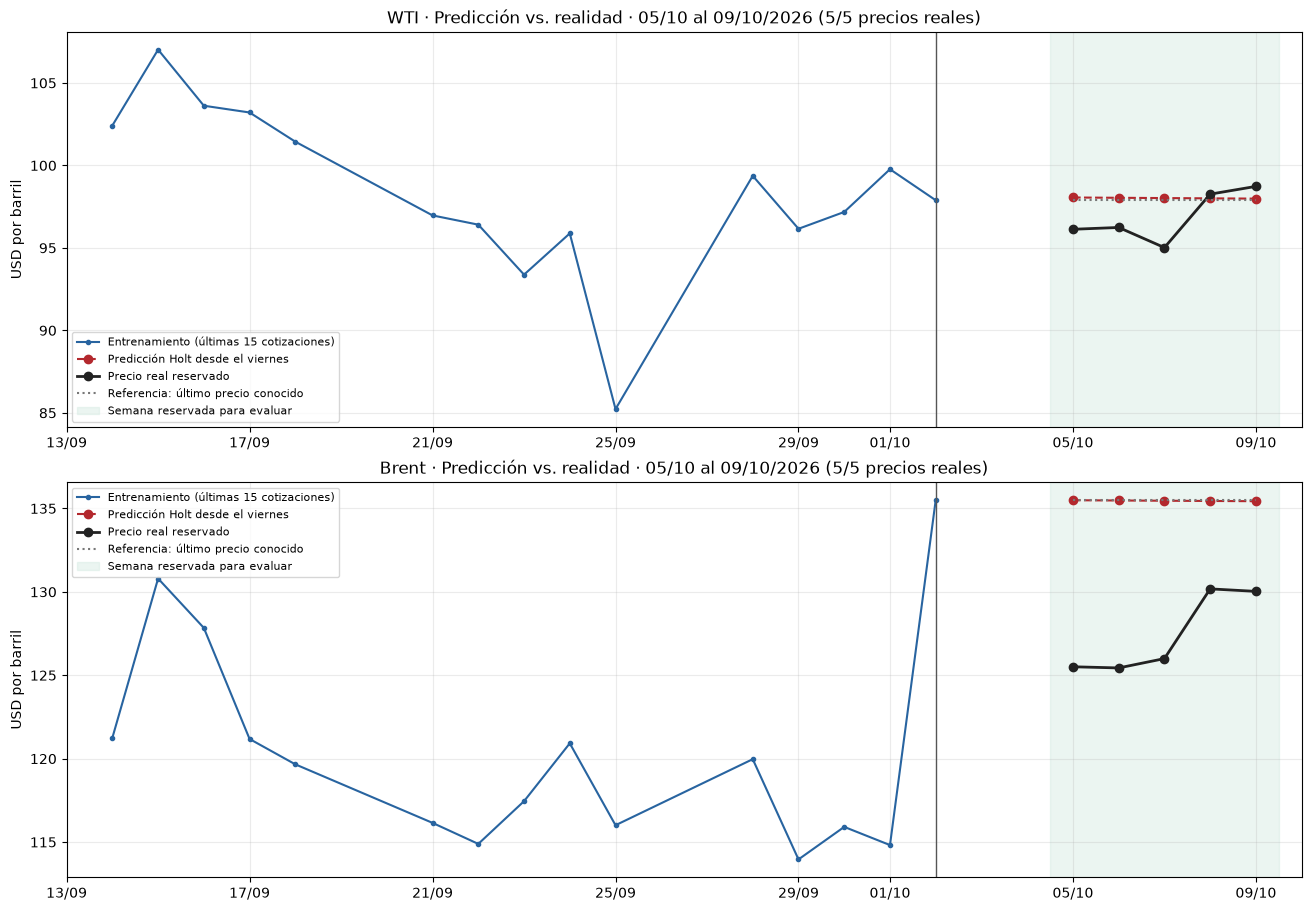

In [4]:
prueba_figura, prueba_ejes = plt_prueba.subplots(
    2, 1, figsize=(13, 9), constrained_layout=True
)
for prueba_ax, (prueba_crudo, prueba_entrenamiento) in zip(
    prueba_ejes, prueba_resultados["entrenamientos"].items()
):
    prueba_tabla_crudo = prueba_comparacion.loc[prueba_comparacion["Crudo"].eq(prueba_crudo)]
    prueba_historia = prueba_entrenamiento.tail(15)
    prueba_ax.plot(prueba_historia.index, prueba_historia,
                   color="#2864A0", marker=".", label="Entrenamiento (últimas 15 cotizaciones)")
    prueba_ax.plot(prueba_tabla_crudo["Fecha"], prueba_tabla_crudo["Holt (USD/barril)"],
                   color="#B3282D", linestyle="--", marker="o", label="Predicción Holt desde el viernes")
    prueba_ax.plot(prueba_tabla_crudo["Fecha"], prueba_tabla_crudo["Real (USD/barril)"],
                   color="#222222", marker="o", linewidth=2, label="Precio real reservado")
    prueba_ax.plot(prueba_tabla_crudo["Fecha"], prueba_tabla_crudo["Último precio (referencia)"],
                   color="#777777", linestyle=":", label="Referencia: último precio conocido")
    prueba_ax.axvline(prueba_resultados["corte"], color="#555555", linewidth=1)
    prueba_ax.axvspan(
        prueba_resultados["fechas"][0] - pd_prueba.Timedelta(hours=12),
        prueba_resultados["fechas"][-1] + pd_prueba.Timedelta(hours=12),
        color="#CFE8DE", alpha=0.4, label="Semana reservada para evaluar",
    )
    prueba_cantidad_reales = int(prueba_tabla_crudo["Real (USD/barril)"].notna().sum())
    prueba_ax.set(
        title=(f"{prueba_crudo} · Predicción vs. realidad · "
               f"{prueba_resultados['fechas'][0]:%d/%m} al {prueba_resultados['fechas'][-1]:%d/%m/%Y} "
               f"({prueba_cantidad_reales}/5 precios reales)"),
        ylabel="USD por barril",
    )
    prueba_ax.set_xlim(prueba_historia.index.min() - pd_prueba.Timedelta(days=1),
                       prueba_resultados["fechas"][-1] + pd_prueba.Timedelta(days=1))
    prueba_ax.xaxis.set_major_formatter(mdates_prueba.DateFormatter("%d/%m"))
    prueba_ax.grid(alpha=0.25)
    prueba_ax.legend(loc="best", fontsize=8)
plt_prueba.show()

## 10.4. Lectura de la prueba

La lectura siguiente se recalcula con las tablas anteriores. Una ventaja en esta semana representa evidencia acotada: para concluir si el modelo predice bien de manera consistente, conviene repetir el mismo corte temporal en varias semanas.

In [5]:
for prueba_crudo in prueba_resultados["entrenamientos"]:
    prueba_resumen_crudo = prueba_metricas.loc[
        prueba_metricas["Crudo"].eq(prueba_crudo)
    ].set_index("Modelo")
    prueba_n = int(prueba_resumen_crudo.loc["Holt amortiguado", "Días evaluados"])
    if not prueba_n:
        display_prueba(Markdown_prueba(
            f"**{prueba_crudo}:** hay cinco predicciones, pero todavía no hay precios reales "
            "de esa semana en el CSV para medir el error."
        ))
        continue
    prueba_mae_holt = prueba_resumen_crudo.loc["Holt amortiguado", "MAE (USD/barril)"]
    prueba_mae_referencia = prueba_resumen_crudo.loc["Último precio", "MAE (USD/barril)"]
    prueba_rmse_holt = prueba_resumen_crudo.loc["Holt amortiguado", "RMSE (USD/barril)"]
    if np_prueba.isclose(prueba_mae_holt, prueba_mae_referencia):
        prueba_lectura = "Holt y repetir el último precio tienen un MAE prácticamente igual"
    elif prueba_mae_holt < prueba_mae_referencia:
        prueba_lectura = "Holt mejora el MAE de repetir el último precio"
    else:
        prueba_lectura = "repetir el último precio tiene menor MAE que Holt"
    display_prueba(Markdown_prueba(
        f"**{prueba_crudo} · {'EVALUACIÓN COMPLETA' if prueba_n == 5 else 'EVALUACIÓN PARCIAL'} "
        f"({prueba_n}/5 días):** error absoluto promedio de Holt = **{prueba_mae_holt:.2f} USD/barril**; "
        f"RMSE = **{prueba_rmse_holt:.2f} USD/barril**. "
        f"La referencia del último precio tiene MAE = **{prueba_mae_referencia:.2f} USD/barril**. "
        f"En los días disponibles, {prueba_lectura}."
    ))
    prueba_faltantes = prueba_comparacion.loc[
        prueba_comparacion["Crudo"].eq(prueba_crudo)
        & prueba_comparacion["Real (USD/barril)"].isna(), "Fecha"
    ]
    if not prueba_faltantes.empty:
        display_prueba(Markdown_prueba(
            "**Fechas sin precio real en el CSV:** "
            + ", ".join(prueba_faltantes.dt.strftime("%d/%m/%Y"))
            + ". Esas fechas no entran en las métricas; actualizar el CSV y volver a ejecutar "
              "esta sección para ampliar la comparación."
        ))

**WTI · EVALUACIÓN COMPLETA (5/5 días):** error absoluto promedio de Holt = **1.54 USD/barril**; RMSE = **1.82 USD/barril**. La referencia del último precio tiene MAE = **1.50 USD/barril**. En los días disponibles, repetir el último precio tiene menor MAE que Holt.

**Brent · EVALUACIÓN COMPLETA (5/5 días):** error absoluto promedio de Holt = **8.03 USD/barril**; RMSE = **8.33 USD/barril**. La referencia del último precio tiene MAE = **8.08 USD/barril**. En los días disponibles, Holt mejora el MAE de repetir el último precio.

<a id="prueba-aleatoria-80-20"></a>

# 11. PRUEBA ALEATORIA · ENTRENAMIENTO Y PRECIOS RESERVADOS

**Objetivo:** elegir al azar un porcentaje de las cotizaciones para entrenar y reconstruir el resto, cuyo precio real se conserva únicamente para evaluar.

El reparto inicial es **80 % para entrenamiento y 20 % para test**, con semilla fija para poder repetir el mismo sorteo. Se realiza un sorteo independiente para WTI y otro para Brent. Se usan las cotizaciones del **período 2, desde el 01/04/2026 hasta la última fecha del CSV local más reciente**. Como las cantidades deben ser enteras, se informa también el porcentaje efectivo de cada grupo.

**Qué mide esta prueba:** estima precios ocultos dentro de una historia que contiene cotizaciones de entrenamiento anteriores y posteriores a las fechas del test. Los precios reales reservados no entran al modelo, pero sí pueden utilizarse otras cotizaciones posteriores a esas fechas. Por eso este punto mide **reconstrucción de datos ocultos**, y no demuestra capacidad para anticipar una semana futura. Las métricas no son directamente comparables con las del punto 10 porque cambian las fechas y la información disponible.

**Cómo ejecutarlo y cambiarlo:** ejecutar las celdas de este punto en orden. Es independiente de los anteriores y lee el CSV sin consultar EIA. En la próxima celda, los comentarios `# CAMBIAR LOS PORCENTAJES`, `# CAMBIAR EL SORTEO` y `# CAMBIAR LA TOLERANCIA` marcan los controles editables.

**NUEVO · Diagnósticos del modelo:** después del ajuste, los apartados **11.1.A, 11.1.B y 11.1.C** muestran los parámetros de Holt, la tendencia y las pruebas de estacionariedad de los precios visibles del entrenamiento. El MAE de Holt y de la referencia lineal se presenta en tablas, gráficos y lectura final.

In [1]:
from pathlib import Path as Path_aleatorio
import matplotlib.dates as mdates_aleatorio
import matplotlib.pyplot as plt_aleatorio
import numpy as np_aleatorio
import pandas as pd_aleatorio
from IPython.display import Markdown as Markdown_aleatorio, display as display_aleatorio
from statsmodels.tsa.statespace.exponential_smoothing import (
    ExponentialSmoothing as Holt_aleatorio,
)

ALEATORIO_INICIO_PERIODO = "2026-04-01"

# ==============================================================
# CAMBIAR LOS PORCENTAJES: EDITAR SOLO ESTE NÚMERO
ALEATORIO_PORCENTAJE_ENTRENAMIENTO = 80  # <<< CAMBIAR ACÁ. Ejemplo: 70 = 70 % / 30 %.
# El porcentaje de test es automáticamente 100 menos este valor.
# Entrenamiento se redondea hacia abajo; el resto queda para test.
# Se requieren al menos 40 cotizaciones para entrenar cada crudo.

# CAMBIAR EL SORTEO: otro entero genera otra selección aleatoria.
ALEATORIO_SEMILLA = 42  # Mantenerlo permite repetir exactamente la misma división.

# CAMBIAR LA TOLERANCIA: error relativo máximo para marcar un caso como cercano.
ALEATORIO_TOLERANCIA_PCT = 5.0  # Error de hasta el 5 % del precio real.
# Es una regla ilustrativa elegida para esta prueba, no una garantía de precisión.
# Después de cambiar un control, ejecutar TODO el PUNTO 11 en orden.
# ==============================================================

aleatorio_raiz = next(
    (p for p in [Path_aleatorio.cwd().resolve(), *Path_aleatorio.cwd().resolve().parents]
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()),
    None,
)
if aleatorio_raiz is None:
    raise FileNotFoundError("Ejecutar desde la raíz del proyecto o desde notebooks/.")
aleatorio_archivos = sorted((aleatorio_raiz / "data").glob("eia_precios_crudo_diarios_*.csv"))
if not aleatorio_archivos:
    raise FileNotFoundError("No se encontró un CSV local de precios diarios en data/.")
aleatorio_archivo = aleatorio_archivos[-1]
aleatorio_datos = pd_aleatorio.read_csv(aleatorio_archivo, keep_default_na=False).drop_duplicates()
if not {"period", "series", "value"}.issubset(aleatorio_datos.columns):
    raise ValueError("El CSV debe contener period, series y value.")
aleatorio_datos = aleatorio_datos[["period", "series", "value"]].copy()
aleatorio_datos["period"] = pd_aleatorio.to_datetime(aleatorio_datos["period"], errors="raise")
aleatorio_datos["value"] = pd_aleatorio.to_numeric(aleatorio_datos["value"], errors="raise")
aleatorio_datos["series"] = aleatorio_datos["series"].astype("string").str.strip()
if aleatorio_datos.isna().any().any() or not np_aleatorio.isfinite(aleatorio_datos["value"]).all():
    raise ValueError("El CSV contiene fechas, series o precios inválidos.")
if aleatorio_datos.duplicated(["period", "series"]).any():
    raise ValueError("Hay más de un precio por fecha y crudo.")

display_aleatorio(Markdown_aleatorio(
    f"**Fuente:** `{aleatorio_archivo.name}`.  \n"
    f"**Reparto solicitado:** {ALEATORIO_PORCENTAJE_ENTRENAMIENTO:g} % entrenamiento / "
    f"{100 - ALEATORIO_PORCENTAJE_ENTRENAMIENTO:g} % test. "
    f"**Semilla:** {ALEATORIO_SEMILLA}. "
    f"**Tolerancia:** error relativo ≤ {ALEATORIO_TOLERANCIA_PCT:g} %."
))

**Fuente:** `eia_precios_crudo_diarios_2024-01_a_2026-10.csv`.  
**Reparto solicitado:** 80 % entrenamiento / 20 % test. **Semilla:** 42. **Tolerancia:** error relativo ≤ 5 %.

## 11.1. Cómo se oculta el test y se ajusta Holt

1. Se ordenan las cotizaciones de cada crudo y se sortean las posiciones del test, sin reemplazo.
2. Esos precios se reemplazan por `NaN` en la entrada del modelo, conservando todas las posiciones temporales. No se mezclan las fechas ni se comprimen los huecos.
3. Se ajusta **Holt con tendencia amortiguada y sin estacionalidad**, mediante la implementación en espacio de estados de statsmodels, que permite tratar los precios ocultos como observaciones ausentes. Es la misma familia de suavizamiento del punto 10, con una implementación adecuada para esta prueba.
4. Se reconstruyen las posiciones ocultas usando el suavizador (`information_set="smoothed"`), que aprovecha las cotizaciones visibles a ambos lados de cada hueco. Solo el test se usa para calcular los errores.

Cada paso representa la siguiente cotización de la serie de ese crudo. Los parámetros y los valores iniciales se estiman con el 80 % visible; los valores de arranque de la optimización también se calculan exclusivamente con ese grupo.

Como referencia sencilla se interpola una línea entre las cotizaciones visibles anterior y posterior al hueco. En los extremos se mantiene el precio visible más cercano. Esa referencia utiliza la misma información disponible para reconstruir; sus valores tampoco se calculan con precios del test.

Referencias de implementación: [suavizamiento exponencial en espacio de estados](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.exponential_smoothing.ExponentialSmoothing.html) y [predicción condicionada a los datos visibles, opción smoothed](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.mlemodel.MLEResults.get_prediction.html).

In [2]:
def evaluar_particion_aleatoria(datos, inicio_periodo, porcentaje_entrenamiento=80,
                               semilla=42, tolerancia_pct=5.0):
    """Ocultar el test al azar y reconstruirlo con Holt usando solo el grupo visible."""
    if not np_aleatorio.isfinite(porcentaje_entrenamiento) or not 0 < porcentaje_entrenamiento < 100:
        raise ValueError("El porcentaje de entrenamiento debe estar entre 0 y 100, sin incluirlos.")
    if not np_aleatorio.isfinite(tolerancia_pct) or tolerancia_pct < 0:
        raise ValueError("La tolerancia debe ser un porcentaje finito, mayor o igual a cero.")
    inicio = pd_aleatorio.Timestamp(inicio_periodo)
    coberturas, tablas_test, metricas, particiones = [], [], [], []
    casos = {}

    for numero, (crudo, codigo) in enumerate({"WTI": "RWTC", "Brent": "RBRTE"}.items()):
        serie = (
            datos.loc[datos["series"].eq(codigo) & datos["period"].ge(inicio)]
            .sort_values("period").set_index("period")["value"].astype(float)
        )
        if not serie.index.is_unique or not np_aleatorio.isfinite(serie).all():
            raise ValueError(f"{crudo}: revisar fechas duplicadas o precios inválidos.")
        total = len(serie)
        n_train = int(np_aleatorio.floor(total * porcentaje_entrenamiento / 100))
        n_test = total - n_train
        if n_train < 40 or n_test < 1:
            raise ValueError(f"{crudo}: se necesitan 40 precios para entrenar y al menos uno para test.")

        # SORTEO: solo se eligen posiciones; los valores de los precios no intervienen.
        rng = np_aleatorio.random.default_rng(semilla + numero)
        posiciones_test = np_aleatorio.sort(rng.choice(total, size=n_test, replace=False))
        mascara_train = np_aleatorio.ones(total, dtype=bool)
        mascara_train[posiciones_test] = False
        precios = serie.to_numpy(dtype=float)

        # EXCLUSIÓN DEL TEST: ningún precio reservado llega al ajuste ni al suavizador.
        observados = np_aleatorio.where(mascara_train, precios, np_aleatorio.nan)
        assert np_aleatorio.isnan(observados[posiciones_test]).all()
        assert int(np_aleatorio.isfinite(observados).sum()) == n_train
        modelo = Holt_aleatorio(
            observados, trend=True, damped_trend=True, seasonal=None,
            initialization_method="estimated",
        )
        # Arranque de la optimización: nivel tomado del primer precio VISIBLE.
        # Se especifica para que un test en las primeras posiciones no genere NaN iniciales.
        arranque = [0.3, 0.03, 0.95, float(observados[mascara_train][0]), 0.0]
        ajuste = modelo.fit(start_params=arranque, method="lbfgs", maxiter=1000, disp=False)
        if not ajuste.mle_retvals.get("converged", False):
            raise RuntimeError(f"{crudo}: el ajuste no convergió; no se publican métricas.")
        reconstruccion = np_aleatorio.asarray(ajuste.get_prediction(
            start=0, end=total - 1, information_set="smoothed"
        ).predicted_mean, dtype=float)
        referencia = np_aleatorio.interp(
            np_aleatorio.arange(total), np_aleatorio.flatnonzero(mascara_train), precios[mascara_train]
        )
        if not np_aleatorio.isfinite(reconstruccion[posiciones_test]).all():
            raise RuntimeError(f"{crudo}: la reconstrucción del test contiene valores inválidos.")

        # Los precios reales reservados se consultan para evaluar recién después del ajuste.
        tabla = pd_aleatorio.DataFrame({
            "Crudo": crudo, "Fecha": serie.index[posiciones_test],
            "Real": precios[posiciones_test], "Holt": reconstruccion[posiciones_test],
            "Referencia lineal": referencia[posiciones_test],
        })
        tabla["Error absoluto Holt"] = (tabla["Holt"] - tabla["Real"]).abs()
        tabla["Error relativo Holt (%)"] = np_aleatorio.divide(
            tabla["Error absoluto Holt"].to_numpy(), np_aleatorio.abs(tabla["Real"].to_numpy()),
            out=np_aleatorio.full(n_test, np_aleatorio.nan), where=tabla["Real"].to_numpy() != 0,
        ) * 100
        tabla["Dentro tolerancia"] = np_aleatorio.where(
            tabla["Real"].eq(0), "No aplica (real 0)",
            np_aleatorio.where(tabla["Error relativo Holt (%)"].le(tolerancia_pct), "Sí", "No"),
        )
        tablas_test.append(tabla)
        particiones.append(pd_aleatorio.DataFrame({
            "Crudo": crudo, "Fecha": serie.index,
            "Grupo": np_aleatorio.where(mascara_train, "Entrenamiento", "Test"),
        }))
        coberturas.append({
            "Crudo": crudo, "Desde": serie.index.min(), "Hasta": serie.index.max(),
            "Total": total, "Entrenamiento (n)": n_train, "Test (n)": n_test,
            "Entrenamiento (%)": n_train / total * 100, "Test (%)": n_test / total * 100,
        })
        for nombre, columna in [("Holt amortiguado (reconstrucción)", "Holt"),
                                ("Interpolación lineal", "Referencia lineal")]:
            errores = (tabla[columna] - tabla["Real"]).to_numpy()
            relativos = np_aleatorio.divide(
                np_aleatorio.abs(errores), np_aleatorio.abs(tabla["Real"].to_numpy()),
                out=np_aleatorio.full(n_test, np_aleatorio.nan), where=tabla["Real"].to_numpy() != 0,
            ) * 100
            relativos_validos = relativos[np_aleatorio.isfinite(relativos)]
            dentro = int(np_aleatorio.sum(relativos_validos <= tolerancia_pct))
            metricas.append({
                "Crudo": crudo, "Modelo": nombre, "Casos test": n_test,
                "MAE (USD/barril)": float(np_aleatorio.abs(errores).mean()),
                "RMSE (USD/barril)": float(np_aleatorio.sqrt((errores ** 2).mean())),
                "MAPE (%)": float(relativos_validos.mean()) if len(relativos_validos) else np_aleatorio.nan,
                "Dentro tolerancia (n)": dentro,
                "Dentro tolerancia (%)": dentro / len(relativos_validos) * 100 if len(relativos_validos) else np_aleatorio.nan,
                "Casos con error relativo": len(relativos_validos),
            })
        casos[crudo] = {"serie": serie, "mascara_train": mascara_train, "ajuste": ajuste}

    return {
        "cobertura": pd_aleatorio.DataFrame(coberturas),
        "particion": pd_aleatorio.concat(particiones, ignore_index=True),
        "test": pd_aleatorio.concat(tablas_test, ignore_index=True),
        "metricas": pd_aleatorio.DataFrame(metricas), "casos": casos,
    }


aleatorio_resultados = evaluar_particion_aleatoria(
    aleatorio_datos, ALEATORIO_INICIO_PERIODO,
    ALEATORIO_PORCENTAJE_ENTRENAMIENTO, ALEATORIO_SEMILLA, ALEATORIO_TOLERANCIA_PCT,
)
aleatorio_cobertura = aleatorio_resultados["cobertura"]
aleatorio_test = aleatorio_resultados["test"]
aleatorio_metricas = aleatorio_resultados["metricas"]

display_aleatorio(Markdown_aleatorio("### Reparto efectivo de las cotizaciones"))
display_aleatorio(aleatorio_cobertura.style.format({
    "Desde": lambda fecha: fecha.strftime("%d/%m/%Y"),
    "Hasta": lambda fecha: fecha.strftime("%d/%m/%Y"),
    "Entrenamiento (%)": "{:.2f}", "Test (%)": "{:.2f}",
}).hide(axis="index"))

### Reparto efectivo de las cotizaciones

Crudo,Desde,Hasta,Total,Entrenamiento (n),Test (n),Entrenamiento (%),Test (%)
WTI,01/04/2026,14/10/2026,138,110,28,79.71,20.29
Brent,01/04/2026,14/10/2026,136,108,28,79.41,20.59


## 11.1.A. PARÁMETROS DEL MODELO · WTI y Brent

Los valores se extraen del **Holt ya ajustado con el entrenamiento**. La interpolación lineal es una referencia calculada entre puntos visibles y no tiene parámetros de suavizamiento.

- **α (alfa):** actualización del nivel; un valor alto da más peso a las nuevas observaciones visibles.
- **β (beta):** actualización del estado de tendencia en la parametrización de espacio de estados utilizada en este punto. Su magnitud no indica por sí sola si el precio sube o baja.
- **φ (phi):** amortiguación de la tendencia. Un valor menor que 1 hace que su contribución pierda fuerza al avanzar el horizonte.
- **Nivel y tendencia iniciales:** estados estimados al comienzo de la serie.
- **Nivel y tendencia finales:** estados estimados a la última fecha del período. La tendencia se expresa en USD por barril y por paso de cotización.

Estos parámetros describen el modelo ajustado; la estacionariedad se explora con pruebas separadas en 11.1.C. No se reutilizan precios del test para calcular los diagnósticos ni para volver a ajustar el modelo.

In [3]:
# PARÁMETROS ESTIMADOS Y TENDENCIA: se reutiliza el ajuste existente, sin volver a entrenar.
def resumir_parametros_tendencia_aleatoria(resultados):
    filas_parametros, filas_tendencia = [], []
    for crudo, caso in resultados["casos"].items():
        ajuste = caso["ajuste"]
        parametros = dict(zip(ajuste.model.param_names, np_aleatorio.asarray(ajuste.params)))
        nombres_estados = list(ajuste.model.state_names)
        nivel_final = float(ajuste.smoothed_state[nombres_estados.index("level"), -1])
        tendencia_final = float(ajuste.smoothed_state[nombres_estados.index("trend"), -1])
        descripciones = [
            ("Alfa · actualización del nivel", float(parametros["smoothing_level"]), "Sin unidad"),
            ("Beta · actualización de la tendencia", float(parametros["smoothing_trend"]), "Sin unidad"),
            ("Phi · amortiguación de la tendencia", float(parametros["damping_trend"]), "Sin unidad"),
            ("Nivel inicial estimado", float(parametros["initial_level"]), "USD/barril"),
            ("Tendencia inicial estimada", float(parametros["initial_trend"]), "USD/barril por cotización"),
            ("Nivel final estimado", nivel_final, "USD/barril"),
            ("Tendencia final estimada", tendencia_final, "USD/barril por cotización"),
        ]
        for nombre, valor, unidad in descripciones:
            filas_parametros.append({"Crudo": crudo, "Parámetro o estado": nombre, "Valor": valor, "Unidad": unidad})

        # SOLO ENTRENAMIENTO: los precios ocultos no entran en la pendiente ni en R².
        visibles = caso["serie"].iloc[caso["mascara_train"]].sort_index()
        dias = np_aleatorio.asarray((visibles.index - visibles.index.min()).days, dtype=float)
        pendiente, intercepto = np_aleatorio.polyfit(dias, visibles.to_numpy(dtype=float), 1)
        estimados_lineales = intercepto + pendiente * dias
        sst = float(np_aleatorio.sum((visibles - visibles.mean()) ** 2))
        r2 = 1 - float(np_aleatorio.sum((visibles - estimados_lineales) ** 2)) / sst if sst > 0 else np_aleatorio.nan
        cambio_proximo = float(parametros["damping_trend"]) * tendencia_final
        direccion = "Prácticamente plana" if np_aleatorio.isclose(cambio_proximo, 0, atol=1e-6) else (
            "Ascendente" if cambio_proximo > 0 else "Descendente"
        )
        filas_tendencia.append({
            "Crudo": crudo, "Cotizaciones visibles": len(visibles),
            "Pendiente global (USD/barril por día)": float(pendiente),
            "R² descriptivo de la recta": r2,
            "Tendencia final Holt (USD/barril por cotización)": tendencia_final,
            "Cambio próximo por tendencia (USD/barril)": cambio_proximo,
            "Dirección final de Holt": direccion,
        })
    return pd_aleatorio.DataFrame(filas_parametros), pd_aleatorio.DataFrame(filas_tendencia)


aleatorio_parametros, aleatorio_tendencias = resumir_parametros_tendencia_aleatoria(aleatorio_resultados)
display_aleatorio(aleatorio_parametros.style.format({"Valor": "{:.6f}"}).hide(axis="index"))

Crudo,Parámetro o estado,Valor,Unidad
WTI,Alfa · actualización del nivel,0.972189,Sin unidad
WTI,Beta · actualización de la tendencia,0.000101,Sin unidad
WTI,Phi · amortiguación de la tendencia,0.977424,Sin unidad
WTI,Nivel inicial estimado,102.528870,USD/barril
WTI,Tendencia inicial estimada,-0.311557,USD/barril por cotización
WTI,Nivel final estimado,101.878799,USD/barril
WTI,Tendencia final estimada,-0.012178,USD/barril por cotización
Brent,Alfa · actualización del nivel,0.856278,Sin unidad
Brent,Beta · actualización de la tendencia,0.000102,Sin unidad
Brent,Phi · amortiguación de la tendencia,0.968885,Sin unidad


## 11.1.B. TENDENCIA · Evolución global y estado final

La **pendiente global** ajusta una recta de precio contra días calendario usando solamente los precios visibles del entrenamiento. Positiva indica una inclinación ascendente en ese período y negativa, descendente. El **R²** describe cuánto de la variación de esos precios recoge esa recta; no mide precisión del test ni es una prueba de significancia de la tendencia.

La **tendencia final de Holt** describe el estado local al final del período, y **φ × tendencia final** es la contribución de la tendencia al siguiente paso. La tendencia global y la final pueden tener signos distintos porque resumen escalas temporales distintas. Una tendencia muy pequeña no garantiza que los próximos precios reales permanezcan constantes.

In [4]:
display_aleatorio(aleatorio_tendencias.style.format({
    "Pendiente global (USD/barril por día)": "{:+.5f}",
    "R² descriptivo de la recta": "{:.4f}",
    "Tendencia final Holt (USD/barril por cotización)": "{:+.6f}",
    "Cambio próximo por tendencia (USD/barril)": "{:+.6f}",
}, na_rep="No aplica").hide(axis="index"))

Crudo,Cotizaciones visibles,Pendiente global (USD/barril por día),R² descriptivo de la recta,Tendencia final Holt (USD/barril por cotización),Cambio próximo por tendencia (USD/barril),Dirección final de Holt
WTI,110,-0.04456,0.0551,-0.012178,-0.011903,Descendente
Brent,108,+0.02518,0.0073,-0.010415,-0.010091,Descendente


## 11.1.C. ESTACIONARIEDAD · Pruebas ADF y KPSS sobre entrenamiento

La estacionariedad significa que propiedades como la media y la dependencia temporal se mantienen estables en el tiempo. No es un parámetro de Holt. Se explora con dos pruebas complementarias, ambas con constante (`regression="c"`) y un nivel de significancia inicial del **5 %**:

- **ADF:** su hipótesis nula es que hay raíz unitaria. Un valor p menor al nivel elegido aporta evidencia contra esa hipótesis.
- **KPSS:** su hipótesis nula es estacionariedad alrededor de una constante. Un valor p pequeño aporta evidencia contra esa estacionariedad.

La lectura combinada informa **compatible con estacionariedad**, **evidencia de no estacionariedad** o **no concluyente**. No rechazar una hipótesis no equivale a demostrarla. Se muestran los estadísticos, valores p y rezagos de cada prueba.

**Alcance exploratorio:** las pruebas usan solo la secuencia de cotizaciones visibles del entrenamiento, ordenada por fecha. Los huecos del sorteo hacen que un rezago pueda abarcar distintas cantidades de días y de cotizaciones originales. Por eso los resultados describen esta submuestra y no demuestran estacionariedad de la serie diaria completa. La primera diferencia es entre **precios visibles consecutivos**, no necesariamente entre dos días consecutivos. No se rellenan huecos con precios reales o estimaciones del test.

Se comparan **precios visibles** y **primeras diferencias entre visibles**. Esa diferenciación es únicamente un diagnóstico: no cambia el modelo, los precios entregados a Holt ni las reconstrucciones del test. KPSS solo tabula valores p entre 0,01 y 0,10; cuando corresponda se muestra el límite, en lugar de presentar el valor como exacto.

Documentación: [ADF en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) y [KPSS en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).

In [5]:
from inspect import signature as signature_aleatorio
import warnings as warnings_aleatorio
from statsmodels.tsa.stattools import adfuller as adfuller_aleatorio, kpss as kpss_aleatorio
from statsmodels.tools.sm_exceptions import InterpolationWarning as InterpolationWarning_aleatorio

# NIVEL DE SIGNIFICANCIA: 0.05 equivale al 5 %. No modifica el entrenamiento.
ALEATORIO_SIGNIFICANCIA = 0.05


def diagnosticar_estacionariedad_aleatoria(resultados, significancia=0.05):
    if not 0 < significancia < 1:
        raise ValueError("La significancia debe estar entre 0 y 1.")
    filas = []
    opciones_adf = {"result_object": True} if "result_object" in signature_aleatorio(adfuller_aleatorio).parameters else {}
    opciones_kpss = {"result_object": True} if "result_object" in signature_aleatorio(kpss_aleatorio).parameters else {}
    for crudo, caso in resultados["casos"].items():
        # SOLO ENTRENAMIENTO: los precios del test se excluyen antes de calcular cualquier test.
        visibles = caso["serie"].iloc[caso["mascara_train"]].sort_index().to_numpy(dtype=float)
        for nombre, valores in [("Precios visibles", visibles),
                                ("Primera diferencia entre visibles", np_aleatorio.diff(visibles))]:
            fila = {"Crudo": crudo, "Serie evaluada": nombre, "n": len(valores)}
            if len(valores) < 20 or np_aleatorio.ptp(valores) == 0:
                fila.update({"ADF": np_aleatorio.nan, "p ADF": np_aleatorio.nan,
                             "Rezagos ADF": 0, "KPSS": np_aleatorio.nan, "p KPSS": np_aleatorio.nan,
                             "p KPSS mostrado": "No aplica", "Rezagos KPSS": 0,
                             "Lectura": "No evaluable: muestra corta o constante"})
                filas.append(fila)
                continue
            adf = adfuller_aleatorio(valores, regression="c", autolag="AIC", **opciones_adf)
            with warnings_aleatorio.catch_warnings(record=True) as avisos:
                warnings_aleatorio.simplefilter("always", InterpolationWarning_aleatorio)
                prueba_kpss = kpss_aleatorio(valores, regression="c", nlags="auto", **opciones_kpss)
            if hasattr(adf, "statistic"):
                estad_adf, p_adf, lag_adf = float(adf.statistic), float(adf.pvalue), int(adf.lags)
            else:
                estad_adf, p_adf, lag_adf = float(adf[0]), float(adf[1]), int(adf[2])
            if hasattr(prueba_kpss, "statistic"):
                estad_kpss, p_kpss, lag_kpss = float(prueba_kpss.statistic), float(prueba_kpss.pvalue), int(prueba_kpss.lags)
            else:
                estad_kpss, p_kpss, lag_kpss = float(prueba_kpss[0]), float(prueba_kpss[1]), int(prueba_kpss[2])
            limitado = any(issubclass(a.category, InterpolationWarning_aleatorio) for a in avisos)
            limite_inferior = limitado and np_aleatorio.isclose(p_kpss, 0.01)
            limite_superior = limitado and np_aleatorio.isclose(p_kpss, 0.10)
            p_mostrado = f"≤ {p_kpss:.2f}" if limite_inferior else (
                f"≥ {p_kpss:.2f}" if limite_superior else f"{p_kpss:.5f}"
            )
            # Respetar los límites tabulados si se cambia la significancia.
            rechaza_kpss = (True if significancia >= p_kpss else None) if limite_inferior else (
                (False if significancia <= p_kpss else None) if limite_superior else p_kpss < significancia
            )
            rechaza_adf = p_adf < significancia
            if rechaza_kpss is None:
                lectura = "No concluyente (p KPSS limitado)"
            elif rechaza_adf and not rechaza_kpss:
                lectura = "Compatible con estacionariedad en nivel"
            elif not rechaza_adf and rechaza_kpss:
                lectura = "Evidencia de no estacionariedad"
            else:
                lectura = "No concluyente (pruebas no coinciden)"
            fila.update({"ADF": estad_adf, "p ADF": p_adf, "Rezagos ADF": lag_adf,
                         "KPSS": estad_kpss, "p KPSS": p_kpss, "p KPSS mostrado": p_mostrado,
                         "Rezagos KPSS": lag_kpss, "Lectura": lectura})
            filas.append(fila)
    return pd_aleatorio.DataFrame(filas)


aleatorio_estacionariedad = diagnosticar_estacionariedad_aleatoria(
    aleatorio_resultados, ALEATORIO_SIGNIFICANCIA
)
display_aleatorio(Markdown_aleatorio(
    f"**Lectura exploratoria con significancia del {ALEATORIO_SIGNIFICANCIA:.0%}. "
    "Entrada: solo cotizaciones visibles del entrenamiento.**"
))
for aleatorio_crudo in aleatorio_resultados["casos"]:
    aleatorio_diagnostico = aleatorio_estacionariedad.loc[aleatorio_estacionariedad["Crudo"].eq(aleatorio_crudo)]
    display_aleatorio(Markdown_aleatorio(f"### {aleatorio_crudo} · Estacionariedad de la submuestra visible"))
    display_aleatorio(aleatorio_diagnostico.drop(columns=["Crudo", "p KPSS"]).style.format({
        "ADF": "{:.4f}", "p ADF": "{:.3g}", "KPSS": "{:.4f}",
    }, na_rep="No aplica").hide(axis="index"))

**Lectura exploratoria con significancia del 5%. Entrada: solo cotizaciones visibles del entrenamiento.**

### WTI · Estacionariedad de la submuestra visible

Serie evaluada,n,ADF,p ADF,Rezagos ADF,KPSS,p KPSS mostrado,Rezagos KPSS,Lectura
Precios visibles,110,-1.8838,0.34,0,0.4107,0.07254,6,No concluyente (pruebas no coinciden)
Primera diferencia entre visibles,109,-10.3765,2.19e-18,0,0.1198,≥ 0.10,1,Compatible con estacionariedad en nivel


### Brent · Estacionariedad de la submuestra visible

Serie evaluada,n,ADF,p ADF,Rezagos ADF,KPSS,p KPSS mostrado,Rezagos KPSS,Lectura
Precios visibles,108,-1.4750,0.546,0,0.3867,0.08288,6,No concluyente (pruebas no coinciden)
Primera diferencia entre visibles,107,-10.9761,7.66e-20,0,0.2726,≥ 0.10,2,Compatible con estacionariedad en nivel


## 11.2. RESULTADOS · Errores y precios del test

**MAE** mide el error absoluto promedio y **RMSE** da mayor peso a errores grandes, ambos en USD por barril. **MAPE** expresa el error absoluto porcentual promedio. Cuanto menores, mejor. Se calculan exclusivamente sobre los precios reservados del test, nunca sobre el entrenamiento.

**Dentro de tolerancia** cuenta las estimaciones cuyo error relativo es menor o igual al porcentaje configurado. Con la configuración inicial, un precio real de 100 USD se considera cercano si la estimación queda entre 95 y 105 USD. El 5 % es una convención editable de este ejercicio. Si hubiera un precio real igual a cero, ese caso se incluye en MAE y RMSE, pero se excluye de MAPE y del porcentaje dentro de tolerancia.

Las tablas por fecha contienen únicamente cotizaciones del test. Todos los precios y errores absolutos se expresan en **USD por barril**.

**MAE en todos los casos:** el resumen incluye WTI y Brent para Holt y para la referencia lineal, siempre sobre el test. En cada tabla por crudo se repiten ambos MAE; cada fila muestra los errores absolutos individuales de ambos métodos. Un error individual no se denomina MAE porque el MAE es el promedio del conjunto.

In [6]:
display_aleatorio(aleatorio_metricas.style.format({
    "MAE (USD/barril)": "{:.4f}", "RMSE (USD/barril)": "{:.2f}",
    "MAPE (%)": "{:.2f}", "Dentro tolerancia (%)": "{:.1f}",
}, na_rep="No aplica").set_properties(
    subset=["MAE (USD/barril)"], **{"font-weight": "bold", "background-color": "#EAF1F8"}
).hide(axis="index"))

for aleatorio_crudo in aleatorio_resultados["casos"]:
    aleatorio_maes_crudo = aleatorio_metricas.loc[aleatorio_metricas["Crudo"].eq(aleatorio_crudo)].set_index("Modelo")
    aleatorio_mae_h = aleatorio_maes_crudo.loc["Holt amortiguado (reconstrucción)", "MAE (USD/barril)"]
    aleatorio_mae_r = aleatorio_maes_crudo.loc["Interpolación lineal", "MAE (USD/barril)"]
    display_aleatorio(Markdown_aleatorio(
        f"### {aleatorio_crudo} · Precios ocultos y reconstruidos\n"
        f"**MAE del test:** Holt = **{aleatorio_mae_h:.4f} USD/barril**; "
        f"referencia lineal = **{aleatorio_mae_r:.4f} USD/barril**."
    ))
    aleatorio_tabla_detalle = aleatorio_test.loc[aleatorio_test["Crudo"].eq(aleatorio_crudo)].copy()
    aleatorio_tabla_detalle["Error absoluto referencia"] = (
        aleatorio_tabla_detalle["Referencia lineal"] - aleatorio_tabla_detalle["Real"]
    ).abs()
    aleatorio_columnas_detalle = ["Fecha", "Real", "Holt", "Referencia lineal", "Error absoluto Holt",
                                  "Error absoluto referencia", "Error relativo Holt (%)", "Dentro tolerancia"]
    display_aleatorio(aleatorio_tabla_detalle[aleatorio_columnas_detalle].style.format({
        "Fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "Real": "{:.2f}", "Holt": "{:.2f}", "Referencia lineal": "{:.2f}",
        "Error absoluto Holt": "{:.4f}", "Error absoluto referencia": "{:.4f}",
        "Error relativo Holt (%)": "{:.2f}",
    }, na_rep="No aplica").hide(axis="index"))

Crudo,Modelo,Casos test,MAE (USD/barril),RMSE (USD/barril),MAPE (%),Dentro tolerancia (n),Dentro tolerancia (%),Casos con error relativo
WTI,Holt amortiguado (reconstrucción),28,2.3467,3.21,2.68,26,92.9,28
WTI,Interpolación lineal,28,2.3476,3.20,2.67,26,92.9,28
Brent,Holt amortiguado (reconstrucción),28,2.2454,3.52,2.10,26,92.9,28
Brent,Interpolación lineal,28,2.2409,3.37,2.12,27,96.4,28


### WTI · Precios ocultos y reconstruidos
**MAE del test:** Holt = **2.3467 USD/barril**; referencia lineal = **2.3476 USD/barril**.

Fecha,Real,Holt,Referencia lineal,Error absoluto Holt,Error absoluto referencia,Error relativo Holt (%),Dentro tolerancia
15/04/2026,93.04,92.73,92.57,0.3124,0.4725,0.34,Sí
16/04/2026,96.46,92.20,92.06,4.2646,4.3950,4.42,Sí
17/04/2026,85.91,91.67,91.56,5.7588,5.6525,6.70,No
24/04/2026,98.42,99.57,99.58,1.1464,1.1600,1.16,Sí
05/05/2026,105.66,105.85,105.97,0.1931,0.3067,0.18,Sí
06/05/2026,98.75,102.17,102.17,3.4250,3.4233,3.47,Sí
10/06/2026,93.68,90.09,90.09,3.5917,3.5925,3.83,Sí
11/06/2026,91.58,88.25,88.28,3.3339,3.3050,3.64,Sí
12/06/2026,88.62,86.41,86.46,2.2139,2.1575,2.50,Sí
22/06/2026,78.94,77.44,77.48,1.4969,1.4550,1.90,Sí


### Brent · Precios ocultos y reconstruidos
**MAE del test:** Holt = **2.2454 USD/barril**; referencia lineal = **2.2409 USD/barril**.

Fecha,Real,Holt,Referencia lineal,Error absoluto Holt,Error absoluto referencia,Error relativo Holt (%),Dentro tolerancia
07/04/2026,138.21,124.19,124.86,14.0205,13.3500,10.14,No
09/04/2026,119.03,120.99,120.59,1.9634,1.5600,1.65,Sí
29/04/2026,124.16,120.15,120.93,4.0144,3.2300,3.23,Sí
11/05/2026,106.11,105.79,105.75,0.3183,0.3633,0.30,Sí
12/05/2026,111.37,107.93,108.01,3.4419,3.3567,3.09,Sí
19/05/2026,114.64,112.50,113.10,2.1397,1.5400,1.87,Sí
20/05/2026,108.93,109.29,109.47,0.3583,0.5400,0.33,Sí
22/05/2026,106.90,104.15,104.30,2.7479,2.6050,2.57,Sí
28/05/2026,95.47,95.81,95.00,0.3363,0.4750,0.35,Sí
08/06/2026,97.46,95.78,95.72,1.6754,1.7400,1.72,Sí


## 11.3. GRÁFICOS · Sorteo y reconstrucción

A la izquierda se distinguen los precios visibles del entrenamiento y los precios ocultos del test, con sus estimaciones. La línea histórica gris se dibuja como referencia visual después de ajustar; sus precios del test no se entregan al modelo.

A la derecha se comparan solamente los casos del test: cuanto más cerca de la diagonal esté un punto, más se aproxima la estimación al precio real. Las líneas punteadas marcan la tolerancia relativa elegida.

**Cada panel muestra el MAE del test de Holt y de la referencia lineal**, en USD por barril. Los cuatro paneles usan las mismas métricas del resumen.

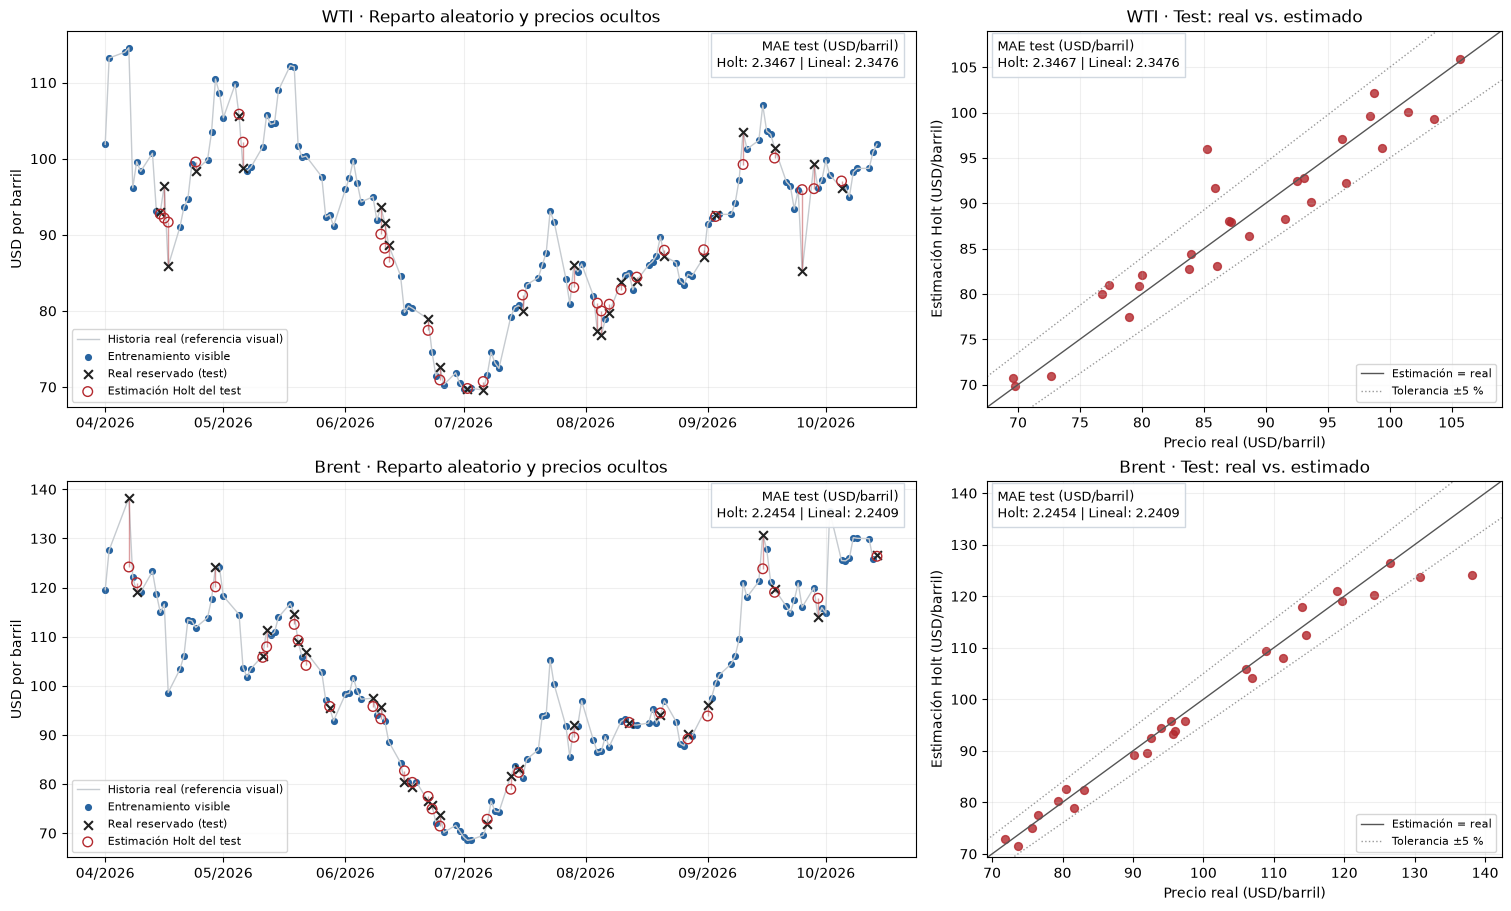

In [7]:
aleatorio_figura, aleatorio_ejes = plt_aleatorio.subplots(
    2, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [1.65, 1]}, constrained_layout=True
)
for aleatorio_fila, (aleatorio_crudo, aleatorio_caso) in enumerate(aleatorio_resultados["casos"].items()):
    aleatorio_serie = aleatorio_caso["serie"]
    aleatorio_train_mask = aleatorio_caso["mascara_train"]
    aleatorio_tabla = aleatorio_test.loc[aleatorio_test["Crudo"].eq(aleatorio_crudo)]
    # MAE DEL TEST: mismo conjunto reservado para ambos métodos y ambos gráficos.
    aleatorio_metricas_crudo = aleatorio_metricas.loc[aleatorio_metricas["Crudo"].eq(aleatorio_crudo)].set_index("Modelo")
    aleatorio_mae_h_grafico = aleatorio_metricas_crudo.loc["Holt amortiguado (reconstrucción)", "MAE (USD/barril)"]
    aleatorio_mae_r_grafico = aleatorio_metricas_crudo.loc["Interpolación lineal", "MAE (USD/barril)"]
    aleatorio_texto_mae = (f"MAE test (USD/barril)\nHolt: {aleatorio_mae_h_grafico:.4f} | "
                          f"Lineal: {aleatorio_mae_r_grafico:.4f}")
    aleatorio_ax = aleatorio_ejes[aleatorio_fila, 0]
    aleatorio_ax.plot(aleatorio_serie.index, aleatorio_serie, color="#C6CBD0", linewidth=1,
                       label="Historia real (referencia visual)")
    aleatorio_ax.scatter(aleatorio_serie.index[aleatorio_train_mask], aleatorio_serie.iloc[aleatorio_train_mask],
                          color="#2864A0", s=17, label="Entrenamiento visible")
    aleatorio_ax.scatter(aleatorio_tabla["Fecha"], aleatorio_tabla["Real"],
                          color="#222222", marker="x", s=40, label="Real reservado (test)", zorder=4)
    aleatorio_ax.scatter(aleatorio_tabla["Fecha"], aleatorio_tabla["Holt"], facecolors="none",
                          edgecolors="#B3282D", s=48, label="Estimación Holt del test", zorder=5)
    aleatorio_ax.vlines(aleatorio_tabla["Fecha"], aleatorio_tabla["Real"], aleatorio_tabla["Holt"],
                         color="#B3282D", alpha=0.45, linewidth=1)
    aleatorio_ax.set(title=f"{aleatorio_crudo} · Reparto aleatorio y precios ocultos", ylabel="USD por barril")
    aleatorio_ax.xaxis.set_major_locator(mdates_aleatorio.MonthLocator())
    aleatorio_ax.xaxis.set_major_formatter(mdates_aleatorio.DateFormatter("%m/%Y"))
    aleatorio_ax.grid(alpha=0.2)
    aleatorio_ax.legend(loc="best", fontsize=8)
    aleatorio_ax.text(0.98, 0.98, aleatorio_texto_mae, transform=aleatorio_ax.transAxes,
                       ha="right", va="top", fontsize=9,
                       bbox={"facecolor": "white", "edgecolor": "#CDD5DE", "alpha": 0.92})

    aleatorio_ax = aleatorio_ejes[aleatorio_fila, 1]
    aleatorio_min = float(aleatorio_tabla[["Real", "Holt"]].min().min()) * 0.97
    aleatorio_max = float(aleatorio_tabla[["Real", "Holt"]].max().max()) * 1.03
    aleatorio_linea = np_aleatorio.linspace(aleatorio_min, aleatorio_max, 100)
    aleatorio_ax.plot(aleatorio_linea, aleatorio_linea, color="#555555", linewidth=1, label="Estimación = real")
    for aleatorio_signo in [-1, 1]:
        aleatorio_ax.plot(aleatorio_linea, aleatorio_linea * (1 + aleatorio_signo * ALEATORIO_TOLERANCIA_PCT / 100),
                           color="#999999", linestyle=":", linewidth=1,
                           label=f"Tolerancia ±{ALEATORIO_TOLERANCIA_PCT:g} %" if aleatorio_signo == 1 else None)
    aleatorio_ax.scatter(aleatorio_tabla["Real"], aleatorio_tabla["Holt"], color="#B3282D", s=32, alpha=0.8)
    aleatorio_ax.set(title=f"{aleatorio_crudo} · Test: real vs. estimado",
                       xlabel="Precio real (USD/barril)", ylabel="Estimación Holt (USD/barril)",
                       xlim=(aleatorio_min, aleatorio_max), ylim=(aleatorio_min, aleatorio_max))
    aleatorio_ax.grid(alpha=0.2)
    aleatorio_ax.legend(loc="lower right", fontsize=8)
    aleatorio_ax.text(0.02, 0.98, aleatorio_texto_mae, transform=aleatorio_ax.transAxes,
                       ha="left", va="top", fontsize=9,
                       bbox={"facecolor": "white", "edgecolor": "#CDD5DE", "alpha": 0.92})
plt_aleatorio.show()

## 11.4. Lectura del experimento

La lectura se calcula a partir de los casos reservados, con la tolerancia elegida. El sorteo se mantiene fijo: no se prueban semillas hasta conseguir un resultado favorable ni se utiliza el test para elegir los parámetros.

El resultado describe esta reconstrucción y esta partición aleatoria. Para evaluar pronósticos futuros sigue correspondiendo el corte cronológico del punto 10. Un error bajo aquí puede apoyarse en precios visibles posteriores a la fecha reconstruida.

In [8]:
for aleatorio_crudo in aleatorio_resultados["casos"]:
    aleatorio_resumen = aleatorio_metricas.loc[aleatorio_metricas["Crudo"].eq(aleatorio_crudo)].set_index("Modelo")
    aleatorio_holt = aleatorio_resumen.loc["Holt amortiguado (reconstrucción)"]
    aleatorio_base = aleatorio_resumen.loc["Interpolación lineal"]
    if np_aleatorio.isclose(aleatorio_holt["MAE (USD/barril)"], aleatorio_base["MAE (USD/barril)"]):
        aleatorio_lectura = "Holt y la interpolación lineal presentan un MAE prácticamente igual"
    elif aleatorio_holt["MAE (USD/barril)"] < aleatorio_base["MAE (USD/barril)"]:
        aleatorio_lectura = "Holt presenta menor MAE que la interpolación lineal de referencia"
    else:
        aleatorio_lectura = "la interpolación lineal de referencia presenta menor MAE que Holt"
    display_aleatorio(Markdown_aleatorio(
        f"**{aleatorio_crudo}:** se evaluaron **{int(aleatorio_holt['Casos test'])} precios ocultos**. "
        f"Holt tuvo MAE = **{aleatorio_holt['MAE (USD/barril)']:.4f} USD/barril**, "
        f"RMSE = **{aleatorio_holt['RMSE (USD/barril)']:.2f} USD/barril** "
        f"y MAPE = **{aleatorio_holt['MAPE (%)']:.2f} %**. "
        f"La referencia lineal tuvo MAE = **{aleatorio_base['MAE (USD/barril)']:.4f} USD/barril**. "
        f"**{int(aleatorio_holt['Dentro tolerancia (n)'])} de "
        f"{int(aleatorio_holt['Casos con error relativo'])} casos "
        f"({aleatorio_holt['Dentro tolerancia (%)']:.1f} %) quedaron dentro del "
        f"±{ALEATORIO_TOLERANCIA_PCT:g} % elegido**. En este sorteo, {aleatorio_lectura}."
    ))
display_aleatorio(Markdown_aleatorio(
    "**Interpretación:** los porcentajes anteriores indican cercanía dentro de una tolerancia "
    "en los precios ocultos de este experimento. Para estimar la precisión al anticipar "
    "precios futuros, revisar la prueba temporal del punto 10."
))

**WTI:** se evaluaron **28 precios ocultos**. Holt tuvo MAE = **2.3467 USD/barril**, RMSE = **3.21 USD/barril** y MAPE = **2.68 %**. La referencia lineal tuvo MAE = **2.3476 USD/barril**. **26 de 28 casos (92.9 %) quedaron dentro del ±5 % elegido**. En este sorteo, Holt presenta menor MAE que la interpolación lineal de referencia.

**Brent:** se evaluaron **28 precios ocultos**. Holt tuvo MAE = **2.2454 USD/barril**, RMSE = **3.52 USD/barril** y MAPE = **2.10 %**. La referencia lineal tuvo MAE = **2.2409 USD/barril**. **26 de 28 casos (92.9 %) quedaron dentro del ±5 % elegido**. En este sorteo, la interpolación lineal de referencia presenta menor MAE que Holt.

**Interpretación:** los porcentajes anteriores indican cercanía dentro de una tolerancia en los precios ocultos de este experimento. Para estimar la precisión al anticipar precios futuros, revisar la prueba temporal del punto 10.